In [304]:
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from scipy.stats import entropy
from sklearn.metrics.pairwise import cosine_similarity


TOD_PATH      = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod"
GREX_PATH     = "/Users/madalina/Documents/M2TAL/stage/grex/grex2"
TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"
# TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/pSUD_Naija-NSC"
PATTERNS_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody.txt"

GREW_PATTERN      = "pattern{X[upos<>PUNCT]}"


for p in (TOD_PATH, GREX_PATH):
    if p not in sys.path:
        sys.path.insert(1, p)

import pyximport
pyximport.install()

import grewpy
from grewpy import Corpus, CorpusDraft, Request

import tod.corpus  # noqa: F401  (registers handlers; keep import)

import grex.data           # noqa: F401
import grex.utils
import grex.features       # noqa: F401
import grex.data_prosody

grewpy.set_config("sud")

# ── Which features to use ────────────────────────────────────────────────
#   "all"      : every prosodic feature (structure + acoustics + contours)
#   "acoustic" : only signal-derived syllable acoustics, i.e. nothing that
#                depends on a human prominence judgment
FEATURE_SET = "acoustic"

ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")


In [305]:
# ── Drop entirely: redundant, unreliable, or too fine-grained ─────────────
FEATURES_TO_DROP = {
    'MeanF0',           # use SemitonesFromUtteranceMean instead (speaker-normalised)
    'MeanF0Step',       # threshold artefact, not a prosodic observation
    'AvgAmplitude',     # recording-condition-dependent
    'MaxAmplitude',     # same
    'SylForm',          # phonetic transcription, too fine-grained
    'AlignBegin',       # timing offset, not linguistic
    'AlignEnd',         # timing offset, not linguistic
    'pauseID',          # identifier, not a feature
    # Before*/Next* equivalents of dropped features:
    'BeforeMeanF0', 'BeforeMeanF0Step', 'BeforeAvgAmplitude',
    'NextMeanF0',   'NextMeanF0Step',   'NextAvgAmplitude',
    'Semiton', 'Overlap', 'Loc', 'Glo', 'Backchannel',
    "AvgAmplitudeNormalized", "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized"
}

# ── Bin into 3 quantile-based categories ──────────────────────────────────
# Note: Duration appears in TWO units in the data:
#   - syllable subnodes: integer ms     (e.g. 289, 167)
#   - pause nodes:       float seconds  (e.g. 0.2695, 0.3328)
# We normalise to ms before binning — see `_normalise_duration` below.
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean',
    'Duration',
    'BeforeSemitonesFromUtterance',
    'NextSemitonesFromUtterance',
    'BeforeDuration',
    'NextDuration',
    'BeforeSemiton',
    'NextSemiton',
    'NextSemitonsFromUtterance',
    'NextBreakLength',
    'AvgAmplitudeGlobalZscore', # naija
    # naija
    "DurationGlobalZscore" # naija
}

BIN_LABELS = {
    'SemitonesFromUtteranceMean':   ['F0_low',       'F0_mid',       'F0_high'],
    'Duration':                     ['Dur_short',    'Dur_mid',      'Dur_long'],
    'BeforeSemitonesFromUtterance': ['BeforeF0_low', 'BeforeF0_mid', 'BeforeF0_high'],
    'NextSemitonesFromUtterance':   ['NextF0_low',   'NextF0_mid',   'NextF0_high'],
    'NextBreakLength':              ['NextBreak_short', 'NextBreak_mid', 'NextBreak_long'],
    
}


In [306]:
# ── SLAM3 contour decomposition ───────────────────────────────────────────
# The *Tone features (FootTone, GroupTone, PackageTone, Period_tone) encode
# pitch contours compositionally:
#
#     [start_pitch][end_pitch]            -- no salient peak (2 chars)
#     [start_pitch][end_pitch][peak][tier] -- with salient peak (4 chars)
#
# pitch ∈ {L, l, m, h, H}  (5 ordinal levels: very low → very high)
# tier  ∈ {1, 2, 3}        (which syllabic tier carries the peak)
# Plus the special atomic value 'Pause'.
#
# Treating these as opaque strings gives ~300 sparse one-hot columns per
# *Tone feature. Decomposing into {start, end, peak, tier, has_peak,
# direction, magnitude} yields ~5 dense sub-features per token instead.

SLAM_TONE_FEATURES = {'FootTone', 'GroupTone', 'PackageTone', 'Period_tone', 'Period', 'PeriodTone'}

# Ordinal mapping used to derive direction & magnitude.
_PITCH_LEVELS = {'L': 1, 'l': 2, 'm': 3, 'h': 4, 'H': 5}
_TIERS = {'1', '2', '3'}


def _parse_slam(label):
    """Parse a SLAM3 contour string into its components.

    Returns a dict {pause, start, end, peak, tier} or None if the label
    doesn't match the SLAM3 grammar (silently skipped downstream).
    """
    if label == 'Pause':
        return {'pause': True, 'start': None, 'end': None,
                'peak': None, 'tier': None}

    if (len(label) == 2
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': None, 'tier': None}

    if (len(label) == 4
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS
            and label[2] in _PITCH_LEVELS and label[3] in _TIERS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': label[2], 'tier': label[3]}

    return None


def _slam_subfeatures(prefix, label):
    """Yield 'sub-feature=value' strings derived from a SLAM3 contour label.

    `prefix` is the path up to and including the *Tone name,
    e.g. 'node:X:child:GroupTone'. Sub-features become
    'node:X:child:GroupTone:start=H', 'node:X:child:GroupTone:direction=rise', …
    """
    parsed = _parse_slam(label)
    if parsed is None:
        return

    if parsed['pause']:
        yield f"{prefix}:pause=True"
        return

    s, e = parsed['start'], parsed['end']
    yield f"{prefix}:start={s}"
    yield f"{prefix}:end={e}"

    # Direction & magnitude on the ordinal pitch scale.
    delta = _PITCH_LEVELS[e] - _PITCH_LEVELS[s]
    if delta > 0:
        direction = 'rise'
    elif delta < 0:
        direction = 'fall'
    else:
        direction = 'flat'
    yield f"{prefix}:direction={direction}"
    yield f"{prefix}:magnitude={abs(delta)}"

    if parsed['peak'] is not None:
        yield f"{prefix}:has_peak=True"
        yield f"{prefix}:peak={parsed['peak']}"
        yield f"{prefix}:tier={parsed['tier']}"
    else:
        yield f"{prefix}:has_peak=False"

In [307]:
def _normalise_duration(value_str):
    """Convert a Duration string to milliseconds regardless of source node type.

    Syllable subnodes store ms (e.g. '289'); pause nodes store seconds
    (e.g. '0.2695'). Heuristic: values < 10 are seconds. A literal 0.0 means
    'missing' (e.g. overlap nodes) → returns None.
    """
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None
    return v * 1000 if v < 10 else v


def _is_sentinel(value_str):
    """True for the '0.0' sentinel that overlap / missing pause nodes carry.

    Without this guard, those zeros would be binned as F0_low rather than
    silently dropped.
    """
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False


def _feature_name(key):
    """Bare feature name from a path-like key, e.g. ('node','X','child','Duration') → 'Duration'."""
    return key[-1]


In [308]:
def collect_continuous_values(all_data_items):
    """Walk every (lex_unit, match, features) triple and collect raw float
    values for each feature in FEATURES_TO_BIN.

    Returns: {feature_name: [float, ...]}
    """
    collector = {f: [] for f in FEATURES_TO_BIN}

    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            # `value` is a string for own/parent/prev/next, or a set of strings
            # for child (a node can have multiple syllables).
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                elif not _is_sentinel(v):
                    try:
                        collector[fname].append(float(v))
                    except (ValueError, TypeError):
                        pass
    return collector


def compute_thresholds(collector, n_bins=3):
    """Quantile boundaries (interior only) per feature.

    Returns: {feature_name: [boundary_1, boundary_2, ...]}
    """
    thresholds = {}
    for fname, values in collector.items():
        if not values:
            continue
        arr = np.array(values)
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
        thresholds[fname] = np.quantile(arr, quantiles).tolist()
    return thresholds


In [309]:
def _bin_value(fname, value_str, thresholds):
    """Continuous string → bin label. Returns None for sentinels / unknowns."""
    if fname not in thresholds or _is_sentinel(value_str):
        return None

    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None

    if v is None:
        return None

    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]


def format_features(features, thresholds):
    """Turn a feature dict into a list of 'k1:k2:...:kn=value' strings.

    Continuous features are binned; dropped features are skipped.
    """
    result = []
    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)

        if fname in FEATURES_TO_DROP:
            continue

        if fname in FEATURES_TO_BIN:
            values = value if isinstance(value, set) else {value}
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
            continue
        
        # if fname == 'Period':
        #     # Strip *, -, and prefix/suffix markers to collapse 16 values down to 4.
        #     for v in values:
        #         cleaned = v.strip('*-')
        #         result.append(f"{prefix}={cleaned}")
        #     # If you want to preserve the pause-adjacency information as its own
        #     # feature, add a boolean:
        #     if any('*' in v or '-' in v for v in values):
        #         result.append(f"{prefix}_pause_adjacent=True")
        #     continue
        
        # SLAM3 contour features: decompose into structural sub-features.
        if fname in SLAM_TONE_FEATURES:
            values = value if isinstance(value, set) else {value}
            for v in values:
                result.extend(_slam_subfeatures(prefix, v))
            continue


        # Categorical: keep as-is.
        if isinstance(value, set):
            for v in value:
                result.append(f"{prefix}={v}")
        else:
            result.append(f"{prefix}={value}")

    return result


def _filter_features(features, excluded_patterns=None, included_patterns=None):
    """Regex-based include/exclude filter over a list of feature strings."""
    import re
    out = []
    for feature in features:
        if excluded_patterns and any(re.search(p, feature) for p in excluded_patterns):
            continue
        if included_patterns and not any(re.search(p, feature) for p in included_patterns):
            continue
        out.append(feature)
    return out


In [310]:
corpus = grewpy.Corpus(TREEBANK_PATH)
draft  = grewpy.CorpusDraft(corpus)

all_matches = corpus.search(
    grewpy.Request(GREW_PATTERN)
        .without("X[InIdiom=Yes]")
        .without("X[Idiom=Yes]")
        .without("X[InTitle=Yes]")
        .without("X[Title=Yes]")
        .without("X[Scrap=Yes]")
        .without("X[Foreign]")
        .without("X[Lang]")
        .without("X-[fixed]->Y")
        .without("Y-[flat:name]->X")
        .without("Y-[goeswith]->X"),
    clustering_keys=["X.form"],
)

# Drop lemmas with fewer than 10 occurrences.
# matches = {k: v for k, v in all_matches.items() if len(v) > 10}
matches=all_matches

# sent_id → {node_id: features}
sent_id_to_sentence = {
    draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft))  # type: ignore
}


In [311]:
with open(PATTERNS_FILE) as f:
    config = yaml.load(f, Loader=yaml.Loader)

templates = grex.utils.FeaturePredicate.from_config(config["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    config["features"], templates=templates,
)

# Raw feature extraction for EVERY occurrence. `matches` is keyed by wordform,
# but that keying is only used to enumerate occurrences — nothing downstream
# depends on it.
all_data_items, occ_meta, n_skipped = [], [], 0
for form, mts in matches.items():
    for m in mts:
        sid, nid = m["sent_id"], str(m["matching"]["nodes"]["X"])
        tf = sent_id_to_sentence.get(sid, {}).get(nid)
        pos = (tf.get("ExtPos") or tf.get("upos")) if tf else None
        if pos is None:
            n_skipped += 1
            continue
        feats = grex.data_prosody.extract_features(draft, m, feature_predicate)
        all_data_items.append((None, m, feats))
        occ_meta.append((form, sid, nid, tf, pos))

print(f"{len(all_data_items)} occurrences extracted ({n_skipped} skipped: no upos)")


33175 occurrences extracted (0 skipped: no upos)


In [312]:
# Compute corpus-wide quantile thresholds, then format every match's features
# (binning the continuous ones, dropping the unwanted ones).
collector  = collect_continuous_values(all_data_items)
thresholds = compute_thresholds(collector, n_bins=3)

print("Computed thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1', 'Q2', 'Q3'])
    print(
        f"  {fname}: <{bounds[0]:.3f} → {labels[0]} | "
        f"<{bounds[1]:.3f} → {labels[1]} | ≥{bounds[1]:.3f} → {labels[2]}"
    )

# Drop 'own' features (the focused node's own attributes — they trivially
# determine its category and would dominate similarity).
EXCLUDED_FEATURE_PATTERNS = [# Own features that would trivially recover POS or aren't prosodic
    'upos', 'lemma', 'form',
    'rel_shallow', 'deprel',
    'Case', 'Definite', 'Gender', 'Mood',
    'Number', 'NumType', 'Person', 'Polarity',
    'Poss', 'PronType', 'Reflex', 'Tense',
    'VerbForm', 'Voice',
    'Number[lex]', 'Person[lex]',
    'Gender[ctxt]', 'Number[ctxt]',
    'ExtPos', 'Foreign', 'Lang', 'Emph',
    'HasSpokenGender', 'HasSpokenNumber',
    'AlignBegin', 'AlignEnd', 'SylForm', 'SpaceAfter',
    # Unmeasurable slope
    'Slope=X',
    # Fused: rare and per-syllable, drops signal-to-noise
    'Fused=Yes',
    # Redundant local slope (keep the Glo scope)
    ':Slope=',
    # Morphological features of dependents — clutter the syntactic space
    'own:Filler=', "Token2=", "rel_deep=", "__MISC__Rel=", "TypePara=", "TypeInherited=", "Truncated=", "Subject=", "Token3", "Token4", "ProminenceFinal=0", "ProminenceInitial=0", "UtteranceMeanF0=0.0",
    "IU", "nucleus", "Layer", "Filler=", "Shared",     
    'ExtPos', "Loc=", "direction=flat", "has_peak=False", 
    # "FootTone:pause", "GroupTone:pause", "PackageTone:pause", "Period_tone:pause", "ProminenceFinal=Pause", "ProminenceInitial=Pause",

                             "AvgAmplitudeLocalZscore", "DurationLocalZscore", "MaxAmplitudeLocalZscore", "DurationNormalized", "MaxAmplitudeGlobalZscore", 
                             "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized", "MaxAmplitudeNormalized", "Coda"
                             ]


# One record per occurrence: identity, token features, formatted prosodic
# features. `cat` here is the BASE category (UPOS/ExtPos) — §3 discovers
# whether and how to refine it; §4 assigns the refined labels.
OCC = []
for (_, _, features), (form, sid, nid, tf, pos) in zip(all_data_items, occ_meta):
    OCC.append({
        "form": form, "cat": pos, "lemma": tf.get("lemma", form),
        "sent_id": sid, "node_id": nid, "tf": tf,
        "features": _filter_features(
            format_features(features, thresholds),
            excluded_patterns=EXCLUDED_FEATURE_PATTERNS),
    })
print(f"{len(OCC)} occurrence records")


Computed thresholds:
  Duration: <133.000 → Dur_short | <199.000 → Dur_mid | ≥199.000 → Dur_long
  NextBreakLength: <0.283 → NextBreak_short | <0.528 → NextBreak_mid | ≥0.528 → NextBreak_long
  SemitonesFromUtteranceMean: <-1.278 → F0_low | <0.529 → F0_mid | ≥0.529 → F0_high
33175 occurrence records


In [313]:
# Attach each occurrence's incoming relation and its position relative to its
# head — ONE search with a named edge (this used to run twice, once for OCC
# and once for the EDGE dict; they are now the same thing).
_key2row = {(r["sent_id"], r["node_id"]): i for i, r in enumerate(OCC)}
for m in corpus.search(grewpy.Request("pattern{e: H -> X; X[upos<>PUNCT]}")):
    row = _key2row.get((m["sent_id"], str(m["matching"]["nodes"]["X"])))
    if row is None or "deprel" in OCC[row]:
        continue
    e = m["matching"]["edges"]["e"]
    lab = e["label"] if isinstance(e, dict) and "label" in e else e
    OCC[row]["deprel"] = (lab if isinstance(lab, str)
                          else ":".join(str(lab[k]) for k in sorted(lab)))
    try:
        OCC[row]["head_dir"] = ("before_head"
                                if float(OCC[row]["node_id"])
                                < float(m["matching"]["nodes"]["H"])
                                else "after_head")
        OCC[row]["head_id"] = str(m["matching"]["nodes"]["H"])
    except ValueError:
        pass
print(f"deprel attached to {sum('deprel' in r for r in OCC)}/{len(OCC)} "
      f"occurrences (the rest are roots)")


deprel attached to 33175/33175 occurrences (the rest are roots)


In [314]:
# ── STEP 0: one 0/1 vector per occurrence ────────────────────────────────
# Nothing about units or categories is decided here.
from math import factorial
from scipy import sparse

EXCLUDE = {"X", "SYM", "NUM"}
MIN_FEATURE_OCC = 10          # a feature seen fewer times is noise

# OCC = [r for r in OCC if r["cat"] not in EXCLUDE]
PILE_RELS = {"repair", "conj:dicto", "conj:reform"}

pile_heads = {(r["sent_id"], r["head_id"]) for r in OCC
              if r.get("deprel") in PILE_RELS and "head_id" in r}
def in_pile(r):
    return (r.get("deprel") in PILE_RELS
            or (r["sent_id"], r["node_id"]) in pile_heads)

before = len(OCC)
removed = Counter(r["cat"] for r in OCC if in_pile(r))
OCC = [r for r in OCC if r["cat"] not in EXCLUDE and not in_pile(r)]
print(f"excluded {before - len(OCC)} occurrences "
      f"({sum(removed.values())} in disfluent piles): {dict(removed.most_common())}")

feat_counts = Counter(f for r in OCC for f in set(r["features"]))
kept = sorted(f for f, n in feat_counts.items() if n >= MIN_FEATURE_OCC)
if FEATURE_SET == "acoustic":
    kept = [f for f in kept
            if any(m in f for m in ACOUSTIC_MEASURES) and "Tone" not in f]
idx2feature = dict(enumerate(kept))
feature2idx = {f: i for i, f in idx2feature.items()}

# OCC_M[i, j] = 1 if occurrence i has feature j
OCC_M = np.zeros((len(OCC), len(kept)), dtype=np.float32)
for a, r in enumerate(OCC):
    for f in r["features"]:
        j = feature2idx.get(f)
        if j is not None:
            OCC_M[a, j] = 1.0

CAT_ROWS = {}
for i, r in enumerate(OCC):
    CAT_ROWS.setdefault(r["cat"], []).append(i)
CATEGORIES = sorted(CAT_ROWS)

print(f"FEATURE_SET={FEATURE_SET}: {len(OCC)} occurrences, "
      f"{len(kept)} features, {len(CATEGORIES)} categories")

excluded 2185 occurrences (2132 in disfluent piles): {'ADP': 466, 'DET': 295, 'VERB': 273, 'PRON': 258, 'AUX': 180, 'NOUN': 180, 'INTJ': 146, 'ADV': 93, 'CCONJ': 62, 'SCONJ': 52, 'PROPN': 47, 'ADJ': 41, 'X': 38, 'NUM': 1}
FEATURE_SET=acoustic: 30990 occurrences, 121 features, 12 categories


In [315]:
# ── STEP 1: lemma or form? ───────────────────────────────────────────────
N_PERM, ALPHA = 1000, 0.05     # 1000 shuffles: p is known to ±0.007 around .05


def dispersion(M, labels):
    """How far the group averages are from the overall average
    (weighted by group size)."""
    grand = M.mean(0)
    out = 0.0
    for g in np.unique(labels):
        sel = labels == g
        d = M[sel].mean(0) - grand
        out += sel.sum() * float(d @ d)
    return out / len(labels)


def n_labellings(counts):
    """Number of different ways to give the form labels to the occurrences."""
    out = factorial(sum(counts))
    for c in counts:
        out //= factorial(c)
    return out


def form_test(rows, rng):
    """p-value: do the forms of this lemma differ more than random
    relabellings of its occurrences?"""
    labels = np.array([OCC[i]["form"] for i in rows])
    M = OCC_M[rows]
    obs = dispersion(M, labels)
    null = np.array([dispersion(M, rng.permutation(labels))
                     for _ in range(N_PERM)])
    return (1 + (null >= obs).sum()) / (N_PERM + 1)


rng = np.random.default_rng(0)
form_tests, unit_rows_table = [], []
for cat in CATEGORIES:
    by_lemma = {}
    for i in CAT_ROWS[cat]:
        by_lemma.setdefault(OCC[i]["lemma"], []).append(i)
    n_multi, pvals = 0, []
    for lemma, rows in by_lemma.items():
        counts = Counter(OCC[i]["form"] for i in rows)
        if len(counts) < 2:
            continue                       # one form: nothing to test
        n_multi += 1
        if n_labellings(list(counts.values())) < 1 / ALPHA:
            continue                       # p could never go below ALPHA
        p = form_test(rows, rng)
        pvals.append(p)
        form_tests.append({"category": cat, "lemma": lemma, "p": p,
                           "forms": ", ".join(f"{f}:{n}" for f, n in counts.most_common())})
    pvals = np.array(pvals)
    share = (pvals < ALPHA).mean() if len(pvals) else np.nan
    unit_rows_table.append({
        "category": cat, "lemmas_with_2+_forms": n_multi, "tested": len(pvals),
        "share_forms_differ": share,
        "unit_key": "form" if len(pvals) and share > 0.5 else "lemma"})

units_table = pd.DataFrame(unit_rows_table)
form_tests = pd.DataFrame(form_tests)      # per-lemma detail, for the paper
KEY = dict(zip(units_table["category"], units_table["unit_key"]))
print(units_table.round(2).to_string(index=False))


def identifier(r):
    return r["form"] if KEY[r["cat"]] == "form" else r["lemma"]

category  lemmas_with_2+_forms  tested  share_forms_differ unit_key
     ADJ                   107      37                0.16    lemma
     ADP                     2       2                0.50    lemma
     ADV                     6       5                0.80     form
     AUX                     3       3                1.00     form
   CCONJ                     0       0                 NaN    lemma
     DET                     9       7                0.57     form
    INTJ                     0       0                 NaN    lemma
    NOUN                   252      62                0.05    lemma
    PRON                    20      14                0.57     form
   PROPN                     0       0                 NaN    lemma
   SCONJ                     4       4                0.25    lemma
    VERB                   252     109                0.36    lemma


In [316]:
# ── Shared: unit vectors, neighbourhoods, stability matrix ───────────────
SIM_THRESHOLD, MAX_NEIGHBOURS = 0.7, 20


def unit_matrix(unit_rows, units):
    """Row of a unit = share of its occurrences that have each feature."""
    return np.vstack([OCC_M[unit_rows[u]].mean(0) for u in units]).astype(float)


def neighbour_weights(sim):
    """W[i, j] = weight of unit j in unit i's neighbourhood.
    Neighbours: similarity >= threshold, at most MAX_NEIGHBOURS, not itself.
    Each row is divided by its total, so it sums to 1."""
    n = len(sim)
    r_, c_, v_ = [], [], []
    n_nbrs = np.zeros(n, dtype=int)
    for i in range(n):
        s = sim[i].copy()
        s[i] = -np.inf
        cand = np.where(s >= SIM_THRESHOLD)[0]
        cand = cand[np.argsort(-s[cand])][:MAX_NEIGHBOURS]
        n_nbrs[i] = len(cand)
        if len(cand):
            w = s[cand]
            r_ += [i] * len(cand)
            c_ += cand.tolist()
            v_ += (w / w.sum()).tolist()
    W = sparse.csr_matrix((v_, (r_, c_)), shape=(n, n))
    return W, n_nbrs > 0, n_nbrs


def stability(W, has, labels, n_cats):
    """Same computation as in the paper.
    S[i, C]   = p_norm(unit i, C)
    mat[C, C'] = mean of p_norm(L, C') over the units L of C (with neighbours)."""
    Y = np.eye(n_cats)[labels]
    freq = Y.mean(0)                              # freq(C) among units
    S = np.asarray(W @ Y) / freq                  # p(L, C) / freq(C)
    S[has] /= S[has].sum(1, keepdims=True)        # renormalise -> p_norm
    counts = Y[has].sum(0)
    mat = (Y[has].T @ S[has]) / np.maximum(counts, 1)[:, None]
    return mat, S



def mean_diag(mat, has, labels, n_cats):
    """Mean self-stability over the categories that have units with neighbours."""
    present = np.bincount(labels[has], minlength=n_cats) > 0
    return np.diag(mat)[present].mean()

In [317]:
# ── STEP 2: which attribute (if any) divides each category? ──────────────
MIN_GROUP_UNITS = 3 # a group needs a few units to have neighbourhoods
KAPPA_MIN = 0.20        # Landis & Koch (1977): below 0.20 = "slight"   
CONTEXT_ATTRS = ("deprel", "head_dir")
UD_FEATURES = {
    "PronType", "NumType", "Poss", "Reflex", "Abbr", "Typo", "Foreign",
    "Gender", "Number", "Case", "Definite", "Degree", "VerbForm", "Mood",
    "Tense", "Aspect", "Voice", "Person", "Polarity", "Polite", "Clusivity",
}


def is_morph_attr(attr):
    return attr.split("[")[0] in UD_FEATURES


def attr_value(r, attr):
    v = r["tf"].get(attr) if is_morph_attr(attr) else r.get(attr)
    return "None" if v is None else str(v)


def candidate_attrs(cat):
    morph = sorted({a for i in CAT_ROWS[cat] for a in OCC[i]["tf"]
                    if is_morph_attr(a)})
    return morph + list(CONTEXT_ATTRS)


def group_map(cat, attr):
    """value -> group. A candidate is eligible only if every attested value
    has at least MIN_GROUP_UNITS units. Pooling rare values into a residual
    group would create a category with no linguistic definition, which cannot
    be interpreted in the results."""
    ids = {}
    for i in CAT_ROWS[cat]:
        r = OCC[i]
        ids.setdefault(attr_value(r, attr), set()).add(identifier(r))
    n_units = {v: len(s) for v, s in ids.items()}
    if len(n_units) < 2 or min(n_units.values()) < MIN_GROUP_UNITS:
        return None
    return {v: v for v in n_units}


def split_test(cat, attr, rng):
    vmap = group_map(cat, attr)
    if vmap is None:
        return None
    unit_rows = {}
    for i in CAT_ROWS[cat]:
        r = OCC[i]
        unit_rows.setdefault((identifier(r), vmap[attr_value(r, attr)]), []).append(i)
    units = sorted(unit_rows)
    groups = sorted({g for _, g in units})
    labels = np.array([groups.index(g) for _, g in units])
    k = len(groups)

    W, has, _ = neighbour_weights(cosine_similarity(unit_matrix(unit_rows, units)))
    row = {"category": cat, "attr": attr, "value_map": vmap,
           "groups": ", ".join(f"{g}:{n}" for g, n in
                               Counter(g for _, g in units).most_common()),
           "units": len(units), "with_nbrs": int(has.sum())}
    if not has.any():
        return {**row, "same": np.nan, "chance": np.nan, "gain": np.nan,
                "kappa": np.nan, "p": np.nan}

    same = mean_diag(stability(W, has, labels, k)[0], has, labels, k)
    null = np.empty(N_PERM)
    for b in range(N_PERM):
        perm = rng.permutation(labels)
        null[b] = mean_diag(stability(W, has, perm, k)[0], has, perm, k)
    chance = null.mean()
    return {**row, "same": same, "chance": chance, "gain": same - chance,
            "kappa": (same - chance) / (1 - chance), 
            "p": (1 + (null >= same).sum()) / (N_PERM + 1)}


rng = np.random.default_rng(0)
split_results, SPLIT = {}, {}
for cat in CATEGORIES:
    rows = [t for a in candidate_attrs(cat)
            if (t := split_test(cat, a, rng)) is not None]
    df = (pd.DataFrame(rows).sort_values("kappa", ascending=False)
            .reset_index(drop=True)) if rows else None
    split_results[cat] = df
    ok = df[(df["p"] < ALPHA) & (df["kappa"] >= KAPPA_MIN)] if df is not None else []
    SPLIT[cat] = (ok.iloc[0]["attr"], ok.iloc[0]["value_map"]) if len(ok) else None

cols = ["attr", "groups", "units", "with_nbrs", "same", "chance", "kappa", "p"]
for cat in CATEGORIES:
    print(f"\n{cat}: split = {SPLIT[cat][0] if SPLIT[cat] else 'none'}")
    if split_results[cat] is not None:
        print(split_results[cat][cols].round(3).to_string(index=False))


ADJ: split = head_dir
    attr                         groups  units  with_nbrs  same  chance  kappa     p
head_dir after_head:447, before_head:74    521        439 0.661   0.499  0.324 0.001
  Number     None:467, Sing:42, Plur:13    522        430 0.358   0.327  0.047 0.211
  Gender     None:304, Masc:132, Fem:98    534        453 0.353   0.331  0.032 0.054

ADP: split = none
    attr                        groups  units  with_nbrs  same  chance  kappa     p
head_dir after_head:31, before_head:23     54         52 0.522    0.49  0.062 0.074

ADV: split = Polarity
    attr                          groups  units  with_nbrs  same  chance  kappa     p
Polarity                 None:185, Neg:7    192        161 0.847   0.477  0.707 0.001
head_dir after_head:149, before_head:116    265        228 0.555   0.497  0.114 0.001

AUX: split = none
    attr                                groups  units  with_nbrs  same  chance  kappa     p
head_dir          after_head:48, before_head:5     53     

In [318]:
print(pd.crosstab([OCC[i].get("deprel") for i in CAT_ROWS["DET"]],
                  [OCC[i].get("head_dir") for i in CAT_ROWS["DET"]]))

col_0       after_head  before_head
row_0                              
comp:obj             1            0
conj:coord           9            0
det                  0         3551
flat                15            0
mod                  0            9


In [319]:
for cat in CATEGORIES:
    ct = pd.crosstab([OCC[i].get("deprel") for i in CAT_ROWS[cat]],
                     [OCC[i].get("head_dir") for i in CAT_ROWS[cat]])
    share = ct.loc[[r for r in ct.index if r in ("repair", "conj:dicto")]].sum() / ct.sum()
    print(f"\n{cat}  (share of each side that is repair/dicto: "
          f"{dict(share.round(2))})")
    print(ct.to_string())



ADJ  (share of each side that is repair/dicto: {'after_head': 0.0, 'before_head': 0.0})
col_0       after_head  before_head
row_0                              
comp:obj            61            0
comp:obl             1            0
comp:pred          309            3
compound             2            0
conj:appos           4            0
conj:coord          45            0
mod                517          506
root                21            0
subj                 0            6

ADP  (share of each side that is repair/dicto: {'after_head': 0.0, 'before_head': 0.0})
col_0           after_head  before_head
row_0                                  
cc                       0            2
comp:obj               100            1
comp:obl               858            8
comp:obl:agent           3            0
comp:pred               45            0
conj:appos              17            0
conj:coord             143            0
discourse                5            3
dislocated:obj           1

3687 units, 121 features, 17 categories
units with >=1 neighbour: 3503 / 3687; neighbours per unit (those with any): median 20
largest standard error of a chance cell: 0.0018


mean self-stability 0.187 (chance: shuffle 0.058, 1/N 0.059); mean kappa 0.136
                           units  kappa
INTJ:head_dir=before_head     16  0.323
SCONJ                          9  0.215
ADP                           31  0.213
ADV:Polarity=Neg               7  0.197
AUX                           48  0.185
ADV:Polarity=None            185  0.169
DET:head_dir=after_head       16  0.151
INTJ:head_dir=after_head      27  0.120
VERB                         599  0.114
PRON:head_dir=before_head     58  0.105
DET:head_dir=before_head      80  0.091
CCONJ                         14  0.091
ADJ:head_dir=after_head      447  0.080
NOUN                        1520  0.078
PRON:head_dir=after_head      83  0.063
PROPN                        473  0.056
ADJ:head_dir=before_head      74  0.053


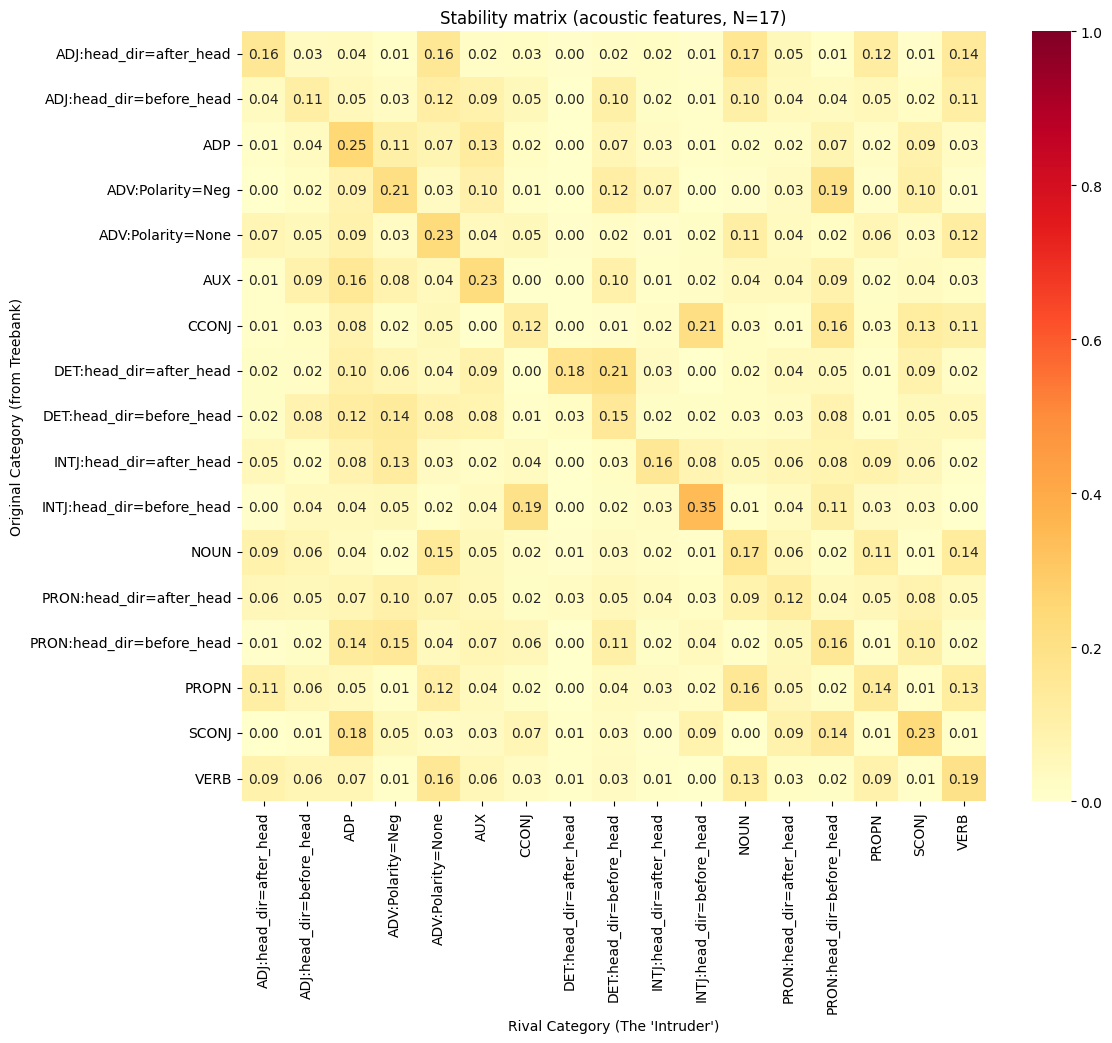

In [320]:
# ── STEP 3: final space and stability matrix ─────────────────────────────
def refined(r):
    s = SPLIT[r["cat"]]
    if s is None:
        return r["cat"]
    attr, vmap = s
    return f"{r['cat']}:{attr}={vmap[attr_value(r, attr)]}"


unit_rows = {}
for i, r in enumerate(OCC):
    unit_rows.setdefault((identifier(r), refined(r)), []).append(i)

unique_units = sorted(unit_rows)
idx2lexunit = dict(enumerate(unique_units))
lexunit2idx = {u: i for i, u in idx2lexunit.items()}
feature_matrix = unit_matrix(unit_rows, unique_units)
n_occ = np.array([len(unit_rows[u]) for u in unique_units], dtype=float)

similarities_matrix = cosine_similarity(feature_matrix)
W, has, n_nbrs = neighbour_weights(similarities_matrix)

cats = sorted({c for _, c in unique_units})
labels = np.array([cats.index(c) for _, c in unique_units])
C = len(cats)

observed, S = stability(W, has, labels, C)

rng = np.random.default_rng(0)
null = np.array([stability(W, has, rng.permutation(labels), C)[0]
                 for _ in range(N_PERM)])
chance = null.mean(0)
chance_se = null.std(0) / np.sqrt(N_PERM)

print(f"{len(unique_units)} units, {feature_matrix.shape[1]} features, {C} categories")
print(f"units with >=1 neighbour: {has.sum()} / {len(has)}; "
      f"neighbours per unit (those with any): median {np.median(n_nbrs[has]):.0f}")
print(f"largest standard error of a chance cell: {chance_se.max():.4f}\n")

diag = pd.DataFrame({
    "units": np.bincount(labels, minlength=C),
    "with_nbrs": np.bincount(labels[has], minlength=C),
    "stability": np.diag(observed),
    "chance_shuffle": np.diag(chance),
    "chance_1/N": 1 / C,
}, index=cats)
diag["kappa"] = ((diag["stability"] - diag["chance_shuffle"])
                 / (1 - diag["chance_shuffle"]))
print(f"\nmean self-stability {diag['stability'].mean():.3f} "
      f"(chance: shuffle {diag['chance_shuffle'].mean():.3f}, 1/N {1 / C:.3f}); "
      f"mean kappa {diag['kappa'].mean():.3f}")
print(diag.sort_values("kappa", ascending=False)[["units", "kappa"]]
      .round(3).to_string())

stability_matrix = pd.DataFrame(observed, index=cats, columns=cats)
chance_matrix = pd.DataFrame(chance, index=cats, columns=cats)
plot_transition_matrix(stability_matrix,
                       f"Stability matrix ({FEATURE_SET} features, N={C})")

# Per-unit scores, used later for bridge words.
scores = {}
for i, u in idx2lexunit.items():
    if not has[i]:
        continue
    p, own = S[i], labels[i]
    rival = np.where(np.arange(C) == own, -1.0, p).argmax()
    scores[u] = {"purity": float(p[own]),
                 "entropy": float(entropy(p[p > 0])),
                 "rival_category": cats[rival],
                 "rival_weight_ratio": float(p[rival])}

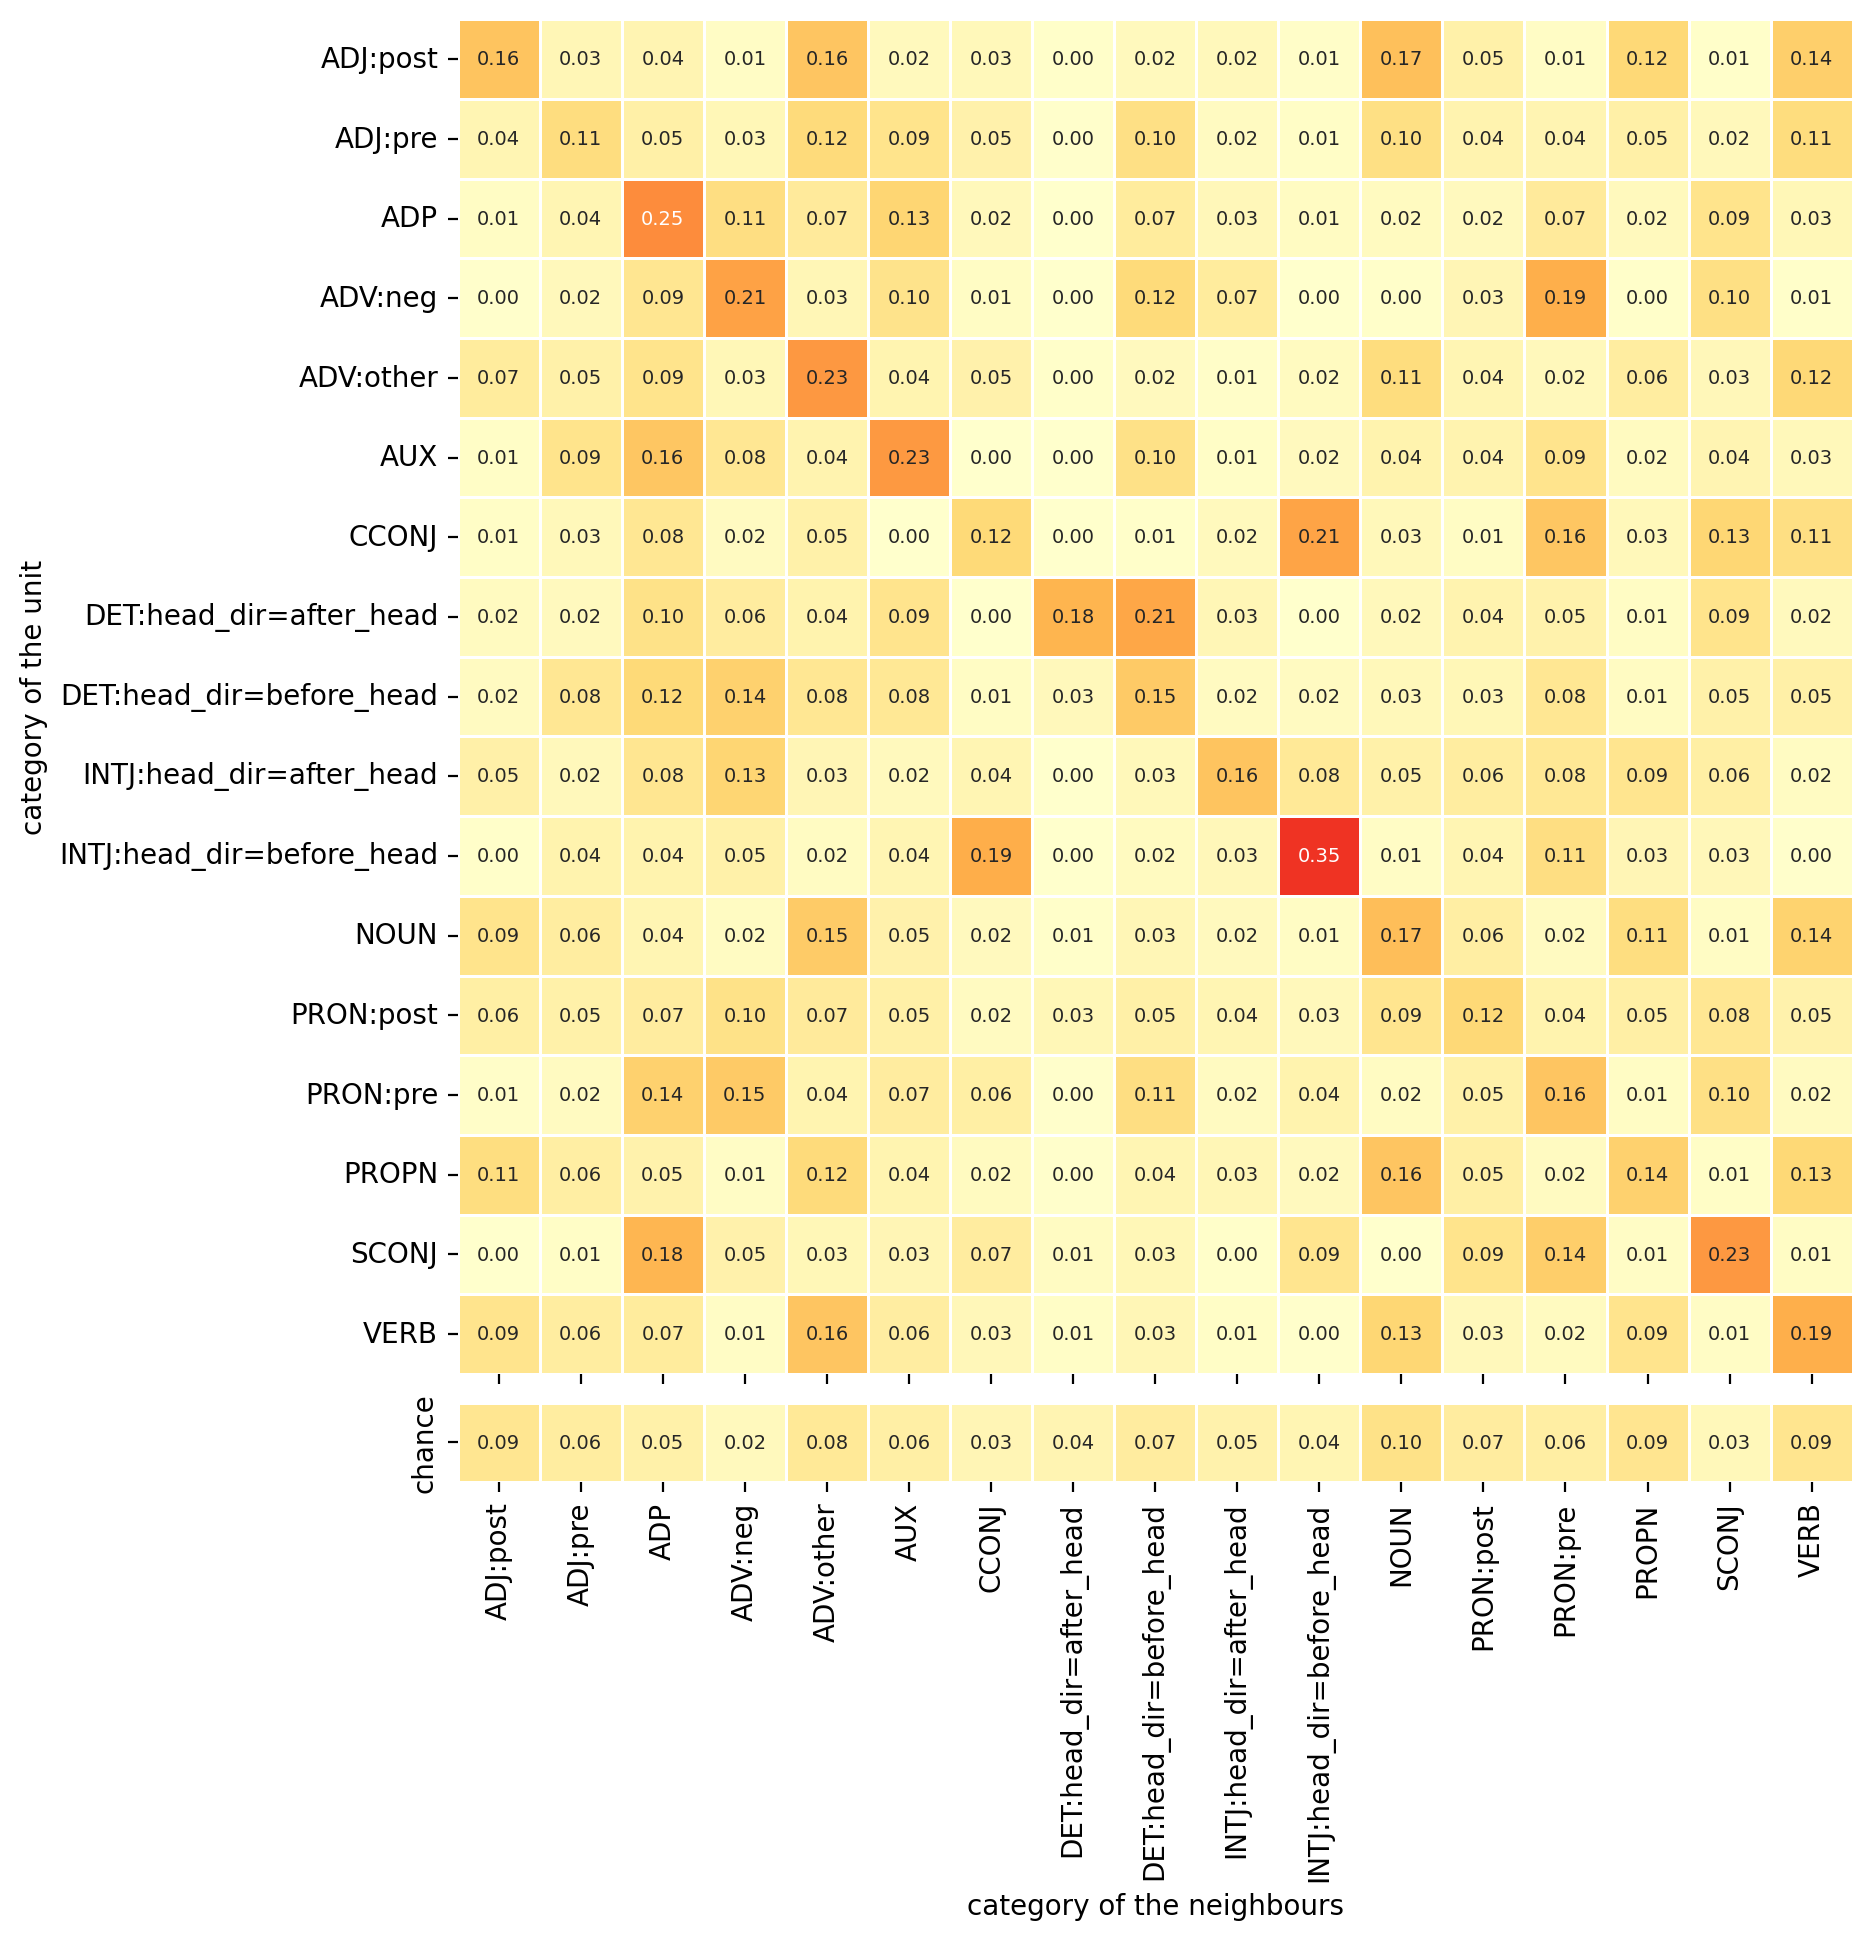

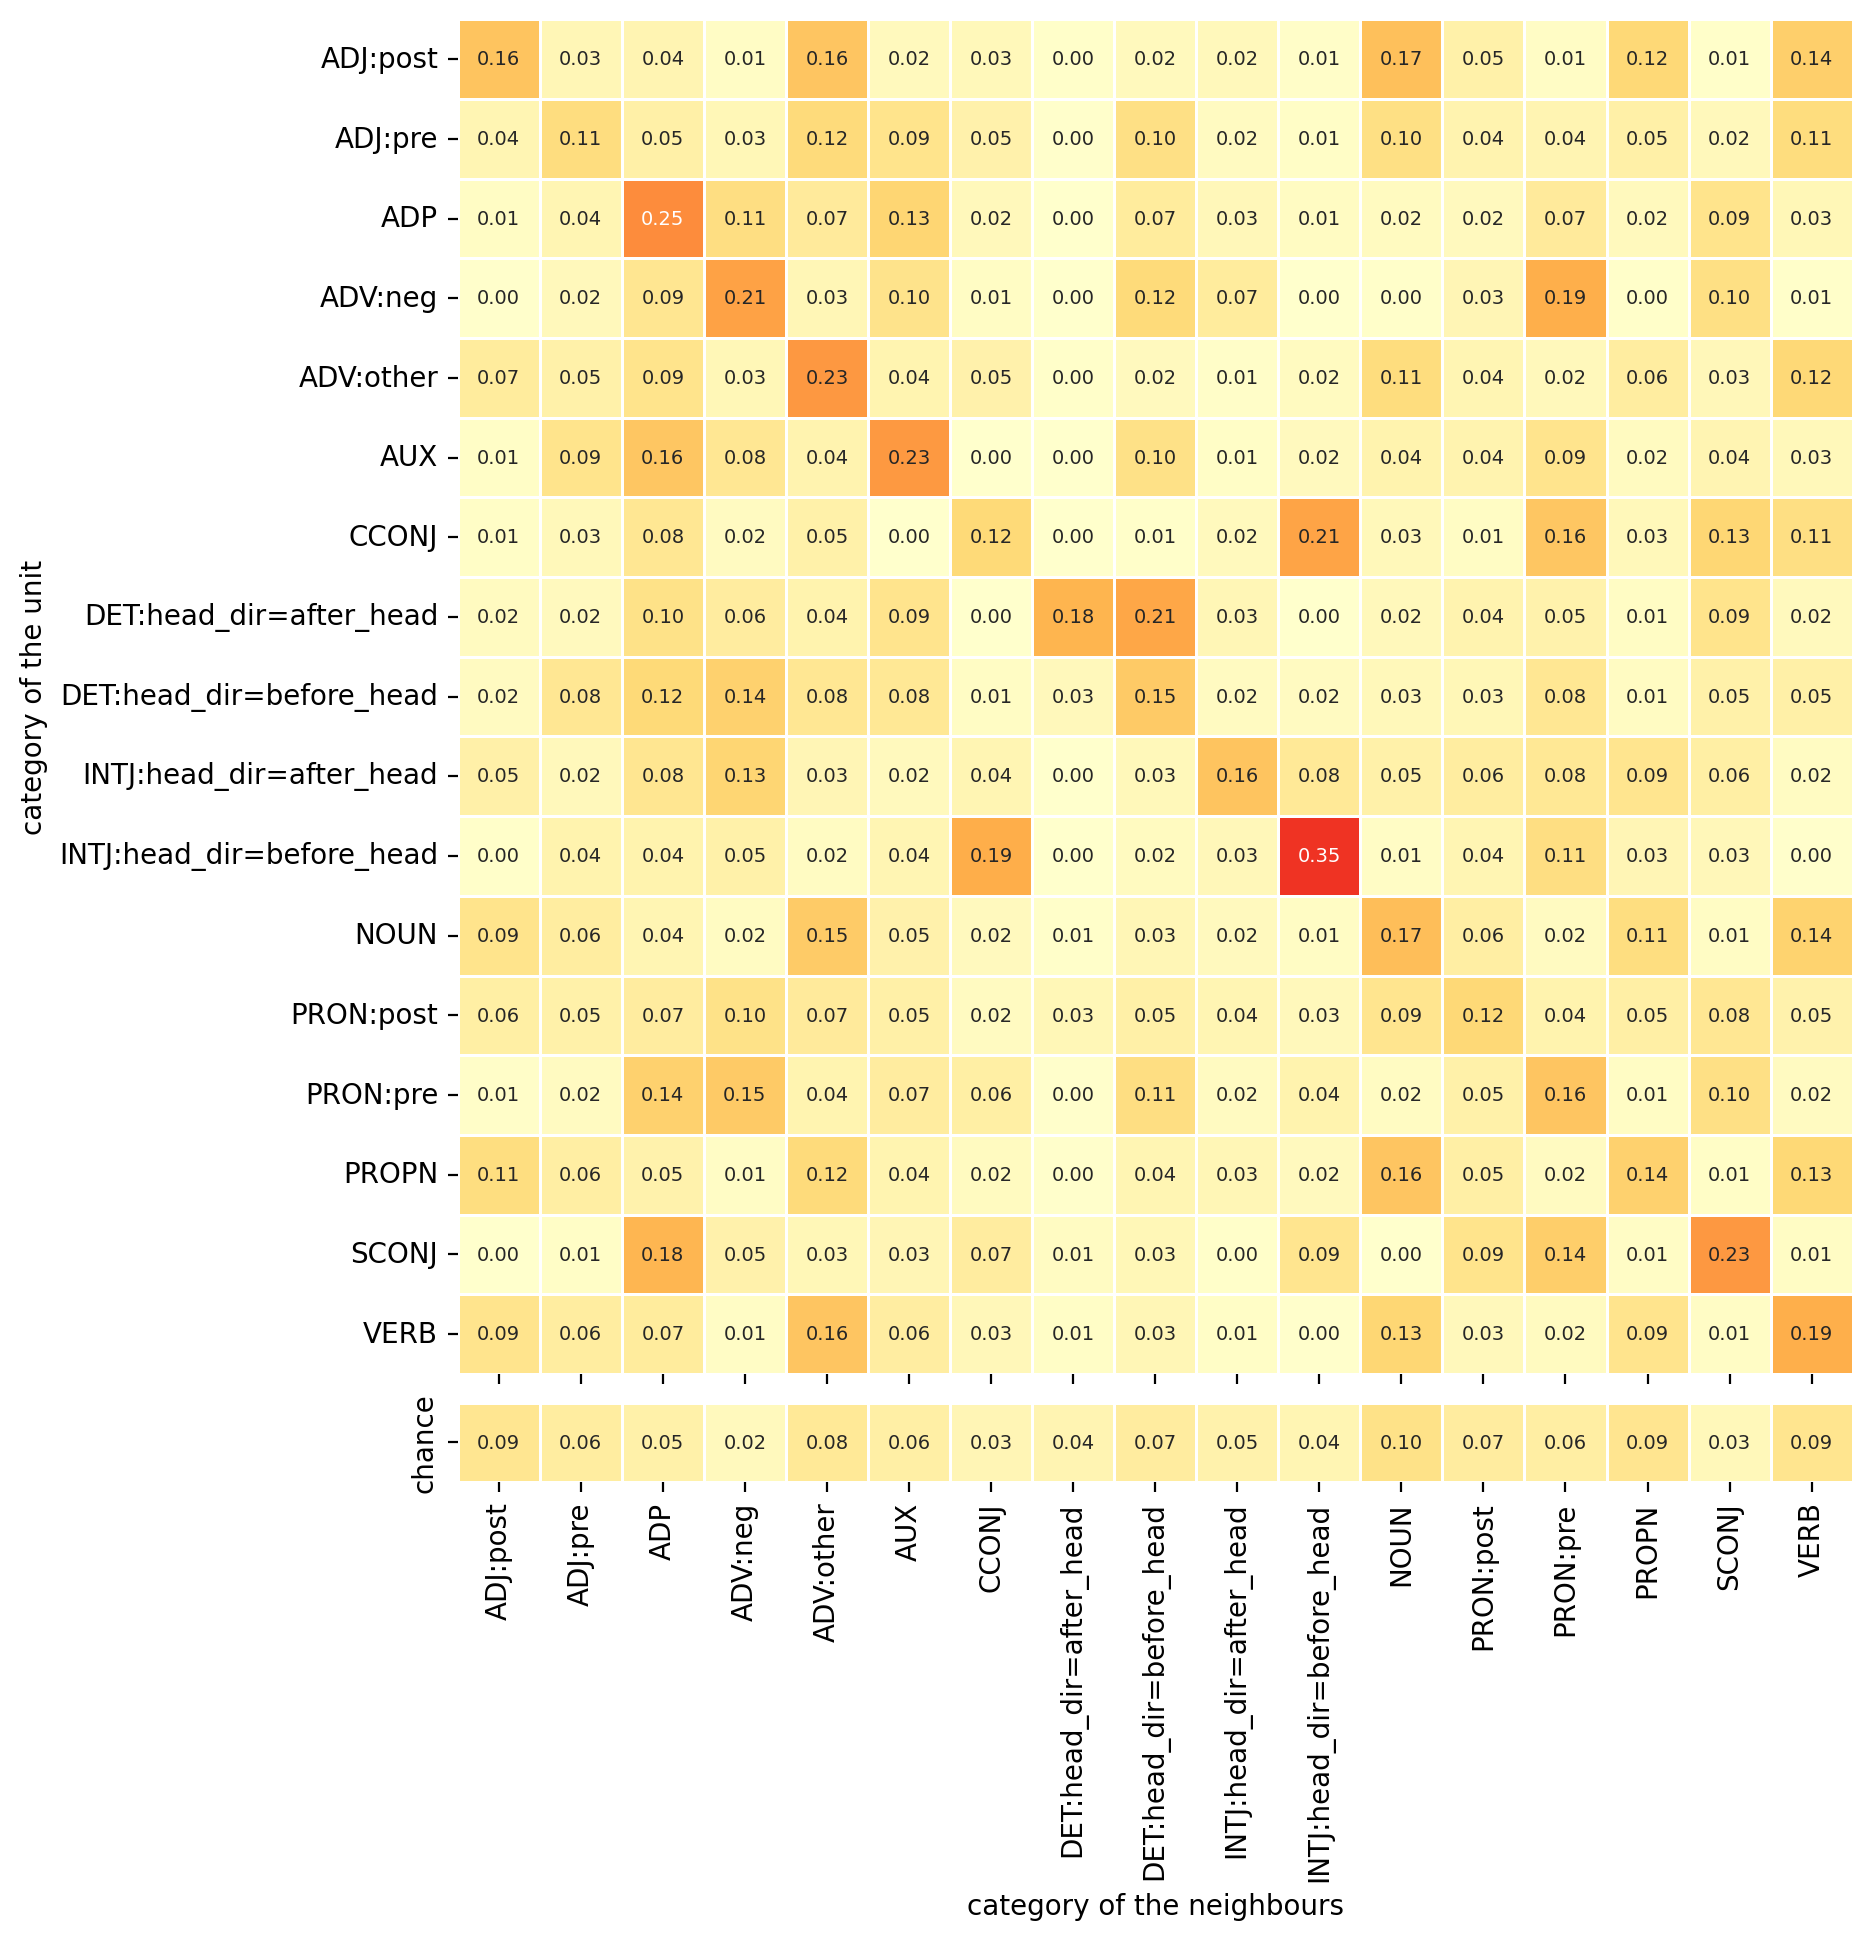

In [321]:
# 2. Chance level per column, and the heatmap with a chance row -----------
chance_col = null.mean(0).mean(0)          # mean over shuffles, then over rows
 
 
def plot_stability(short=None, path=None, vmax=0.5):
    lab = [short.get(c, c) for c in cats] if short else cats
    fig, (ax, axc) = plt.subplots(
        2, 1, figsize=(9, 9.5), dpi=200, sharex=True,
        gridspec_kw={"height_ratios": [C, 1], "hspace": 0.04})
    kw = dict(cmap="YlOrRd", vmin=0, vmax=vmax, annot=True, fmt=".2f",
              annot_kws={"size": 7}, cbar=False, linewidths=0.4, linecolor="white")
    sns.heatmap(observed, ax=ax, xticklabels=lab, yticklabels=lab, **kw)
    sns.heatmap(chance_col[None, :], ax=axc, xticklabels=lab,
                yticklabels=["chance"], **kw)
    axc.tick_params(axis="x", rotation=90)
    ax.set_ylabel("category of the unit"); axc.set_xlabel("category of the neighbours")
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig

plot_stability(short=SHORT, path="stab_matrix_full.png")

In [339]:
ac = [f for f in idx2feature.values() if any(m in f for m in ACOUSTIC_MEASURES) and "Tone" not in f]
print(len(ac)); print(Counter(_name(f).split("=")[0] for f in ac))

121
Counter({'childSyl1:AvgHeightGlo': 3, 'childSyl1:Duration': 3, 'childSyl1:PitchRangeGlo': 3, 'childSyl1:SemitonesFromUtteranceMean': 3, 'childSyl1:SlopeGlo': 3, 'childSyl2:AvgHeightGlo': 3, 'childSyl2:Duration': 3, 'childSyl2:PitchRangeGlo': 3, 'childSyl2:SemitonesFromUtteranceMean': 3, 'childSyl2:SlopeGlo': 3, 'childSyl3:AvgHeightGlo': 3, 'childSyl3:Duration': 3, 'childSyl3:PitchRangeGlo': 3, 'childSyl3:SemitonesFromUtteranceMean': 3, 'childSyl3:SlopeGlo': 3, 'childSyl4:AvgHeightGlo': 3, 'childSyl4:Duration': 3, 'childSyl4:PitchRangeGlo': 3, 'childSyl4:SemitonesFromUtteranceMean': 3, 'childSyl4:SlopeGlo': 3, 'childSyl5:AvgHeightGlo': 3, 'childSyl5:Duration': 3, 'childSyl5:PitchRangeGlo': 3, 'childSyl5:SemitonesFromUtteranceMean': 3, 'childSyl5:SlopeGlo': 3, 'childSylExt1:AvgHeightGlo': 3, 'childSylExt1:Duration': 3, 'childSylExt1:PitchRangeGlo': 3, 'childSylExt1:SemitonesFromUtteranceMean': 3, 'childSylExt1:SlopeGlo': 3, 'nextSyl:AvgHeightGlo': 3, 'nextSyl:Duration': 3, 'nextSyl:P

In [322]:
amap = {"DET": "DET:head_dir=before_head"}          # NOUN:pre, VERB:* do not exist here
pairs = [("DET","ADP"), ("CCONJ","PRON:head_dir=before_head"), ("ADV:Polarity=Neg","SCONJ"),
         ("VERB:head_dir=before_head","ADV:Polarity=Neg"), ("CCONJ","SCONJ"),
         ("PRON:head_dir=after_head","ADV:Polarity=Neg"), ("ADJ:head_dir=after_head","ADV:Polarity=None"),
         ("NOUN:head_dir=before_head","VERB:head_dir=after_head"), ("ADJ:head_dir=before_head","AUX"),
         ("ADJ:head_dir=before_head","DET"), ("ADJ:head_dir=before_head","ADP"),
         ("ADJ:head_dir=before_head","ADV:Polarity=Neg")]
for a, b in pairs:
    A, B = amap.get(a, a), amap.get(b, b)
    if A in cats and B in cats:
        i, j = cats.index(A), cats.index(B)
        print(f"{a:28s} {b:28s} {observed[i, j]:.2f} ({observed[i, i]:.2f})")
    else:
        print(f"{a:28s} {b:28s} --")

DET                          ADP                          0.12 (0.15)
CCONJ                        PRON:head_dir=before_head    0.16 (0.12)
ADV:Polarity=Neg             SCONJ                        0.10 (0.21)
VERB:head_dir=before_head    ADV:Polarity=Neg             --
CCONJ                        SCONJ                        0.13 (0.12)
PRON:head_dir=after_head     ADV:Polarity=Neg             0.10 (0.12)
ADJ:head_dir=after_head      ADV:Polarity=None            0.16 (0.16)
NOUN:head_dir=before_head    VERB:head_dir=after_head     --
ADJ:head_dir=before_head     AUX                          0.09 (0.11)
ADJ:head_dir=before_head     DET                          0.10 (0.11)
ADJ:head_dir=before_head     ADP                          0.05 (0.11)
ADJ:head_dir=before_head     ADV:Polarity=Neg             0.03 (0.11)


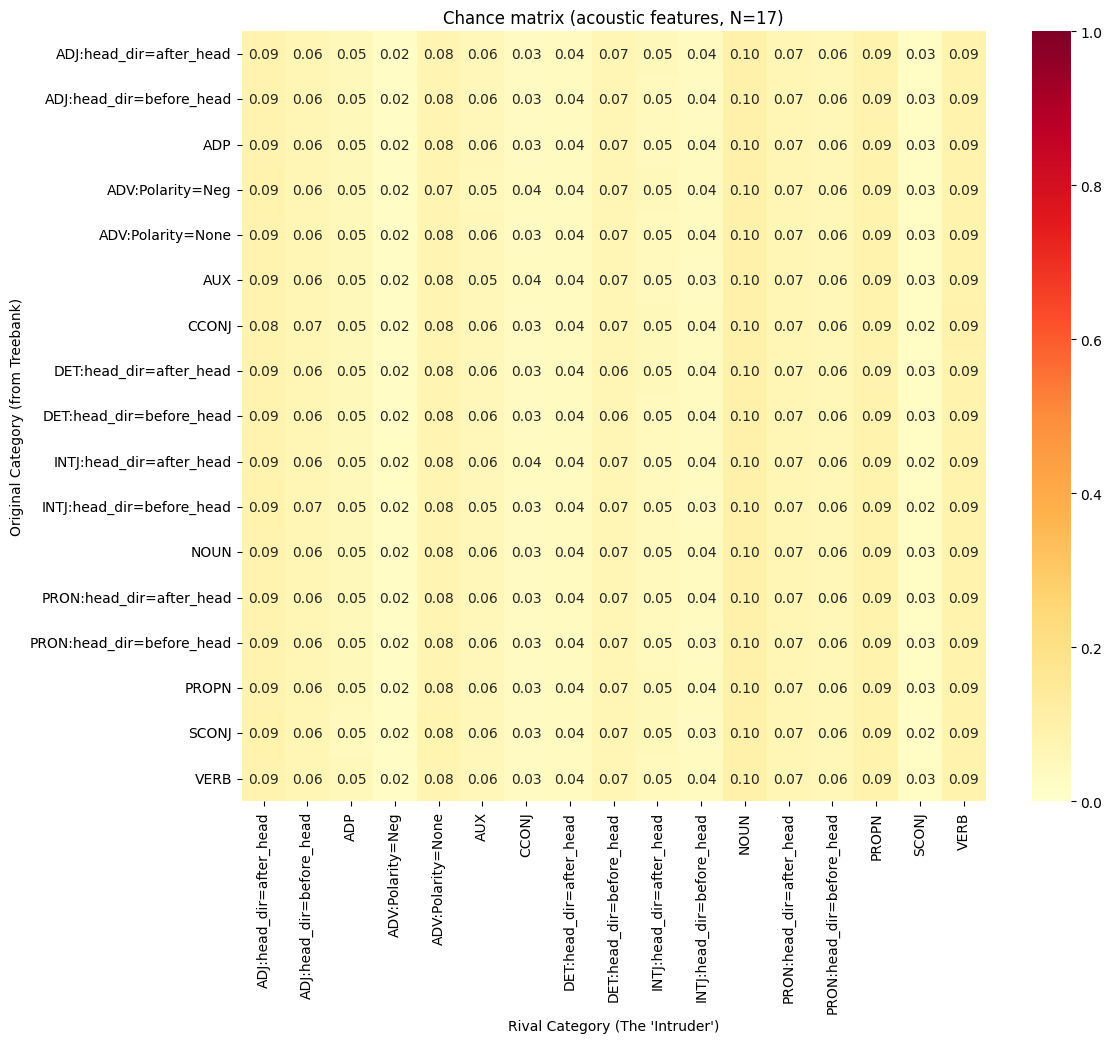

In [323]:
plot_transition_matrix(chance_matrix,
                       f"Chance matrix ({FEATURE_SET} features, N={C})")

In [324]:
def build_transition_matrix(similarity, idx2lexunit, category_freqs,
                            sim_threshold=0.7, max_neighbours=20):
    """Square row-stochastic DataFrame indexed by POS category."""
    rows = []

    for idx, lex_unit in idx2lexunit.items():
        current_cat = lex_unit[1]

        candidate_idx = np.where(similarity[idx] > sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]

        if not neighbours:
            continue

        raw_weights = {}
        total_raw_weight = 0.0
        for n_idx in neighbours:
            n_cat = idx2lexunit[n_idx][1]
            sim = similarity[idx][n_idx]
            raw_weights[n_cat] = raw_weights.get(n_cat, 0) + sim
            total_raw_weight += sim

        norm_probs = {
            cat: (w / total_raw_weight) / category_freqs[cat]
            for cat, w in raw_weights.items()
        }
        total = sum(norm_probs.values())
        for cat in norm_probs:
            norm_probs[cat] /= total
            rows.append({"Original": current_cat, "Neighbor": cat,
                         "Weight":   norm_probs[cat]})

    df = pd.DataFrame(rows)

    # Force the matrix to be square — add any missing rows/columns as zero.
    all_categories = sorted(set(df['Original']) | set(df['Neighbor']))
    matrix = (df.groupby(['Original', 'Neighbor'])['Weight']
                .sum()
                .unstack(fill_value=0)
                .reindex(index=all_categories, columns=all_categories,
                         fill_value=0))

    # Row-normalise (rows that summed to 0 stay 0).
    row_sums = matrix.sum(axis=1).replace(0, 1)
    matrix_to_return = matrix.div(row_sums, axis=0)
    matrix_to_return = matrix_to_return.drop(index='X', columns='X', errors='ignore')
    return matrix_to_return


def plot_transition_matrix(matrix, title, drop_categories=()):
    """Heatmap of a transition matrix. `drop_categories` removes rows + cols
    (useful for hiding 'X' / 'SYM' which are usually noise)."""
    if drop_categories:
        keep = [c for c in matrix.index if c not in drop_categories]
        matrix = matrix.loc[keep, keep]
        print(matrix)
    plt.figure(figsize=(12, 10))
    sns.heatmap(matrix, annot=True, cmap="YlOrRd", fmt=".2f", vmin=0, vmax=1,)
    plt.title(title)
    plt.ylabel("Original Category (from Treebank)")
    plt.xlabel("Rival Category (The 'Intruder')")
    plt.show()


In [325]:
stability_matrix

,ADJ:head_dir=after_head,ADJ:head_dir=before_head,ADP,ADV:Polarity=Neg,ADV:Polarity=None,AUX,CCONJ,DET:head_dir=after_head,DET:head_dir=before_head,INTJ:head_dir=after_head,INTJ:head_dir=before_head,NOUN,PRON:head_dir=after_head,PRON:head_dir=before_head,PROPN,SCONJ,VERB
ADJ:head_dir=after_head,0.158443,0.032637,0.037212,0.011457,0.158000,0.022262,0.025864,0.004277,0.023204,0.024111,0.006109,0.165159,0.048833,0.010034,0.124982,0.005407,0.142006
ADJ:head_dir=before_head,0.036721,0.113223,0.054325,0.030097,0.117715,0.093236,0.047860,0.002654,0.102692,0.016001,0.009197,0.103757,0.041350,0.037589,0.054280,0.024754,0.114550
ADP,0.011900,0.036970,0.250234,0.109291,0.071680,0.130813,0.023524,0.000000,0.066828,0.028971,0.014496,0.017932,0.019953,0.072196,0.021674,0.093417,0.030121
ADV:Polarity=Neg,0.002036,0.023715,0.085654,0.213594,0.032387,0.095282,0.012154,0.000000,0.120614,0.068249,0.000000,0.004614,0.034275,0.192426,0.004539,0.104815,0.005648
ADV:Polarity=None,0.066806,0.050191,0.092756,0.030060,0.232382,0.040921,0.047363,0.004646,0.020540,0.007516,0.018836,0.114265,0.035174,0.023952,0.063656,0.027483,0.123453
AUX,0.008137,0.093113,0.156080,0.083961,0.041799,0.229808,0.000000,0.000000,0.101053,0.009151,0.019664,0.043128,0.041882,0.090400,0.017918,0.038093,0.025813
CCONJ,0.008144,0.025496,0.082157,0.016827,0.050256,0.000000,0.121272,0.000000,0.005173,0.022460,0.212328,0.026833,0.011839,0.155521,0.027033,0.127847,0.106814
DET:head_dir=after_head,0.018324,0.020419,0.099087,0.064491,0.044162,0.090574,0.000000,0.182744,0.206834,0.031589,0.000000,0.024969,0.042338,0.045810,0.013372,0.091907,0.023379
DET:head_dir=before_head,0.017055,0.082733,0.121210,0.138125,0.082065,0.079075,0.013038,0.025172,0.150089,0.017504,0.015968,0.026188,0.030521,0.083668,0.014760,0.049658,0.053169
INTJ:head_dir=after_head,0.052037,0.024024,0.084334,0.130500,0.033665,0.022769,0.036115,0.000000,0.025671,0.159788,0.076499,0.049844,0.063137,0.079349,0.089592,0.057226,0.015451


In [326]:
import re
import matplotlib.pyplot as plt
 
FEATS = [idx2feature[j] for j in range(feature_matrix.shape[1])]
 
 
def _name(f):
    return re.sub(r"^node:X:", "", f)
 
 
def variable(f):          # "own:Group=Begin" -> "own:Group"
    return _name(f).rsplit("=", 1)[0]
 
 
def slot(f):              # "own", "prev", "next", "childSyl1", "prevSyl", ...
    return _name(f).split(":")[0]
 
 
def position(f):
    s = slot(f)
    return "before" if s.startswith("prev") else "after" if s.startswith("next") else "own"
 
 
def tier(f):
    return "syllable" if "Syl" in slot(f) else "token"
 
 
REGION = np.array([f"{position(f)} / {tier(f)}" for f in FEATS])
REGION_ORDER = ["before / token", "before / syllable", "own / token",
                "own / syllable", "after / token", "after / syllable"]
 
 
# ── 4a. Which cells are overlaps? ────────────────────────────────────────
# A cell C0 -> C1 is an overlap when
#   (1) C1 takes at least as much of C0's neighbourhoods as C0 itself, and
#   (2) the cell is above what shuffled labels give for that same cell.
# The chance level depends on the COLUMN (the neighbour category), not the row:
# large categories get a higher chance value, because a unit with only one or
# two neighbours gets p_norm = 1 for whatever category those neighbours are in,
# and that is most often a large category.
def overlap_table(alpha=ALPHA):
    rows = []
    for a, c0 in enumerate(cats):
        for b, c1 in enumerate(cats):
            if a != b and observed[a, b] >= observed[a, a]:
                rows.append({"C0": c0, "C1": c1,
                             "cell": observed[a, b], "self": observed[a, a],
                             "chance": null[:, a, b].mean(),
                             "p": (1 + (null[:, a, b] >= observed[a, b]).sum())
                                  / (N_PERM + 1)})
    t = pd.DataFrame(rows, columns=["C0", "C1", "cell", "self", "chance", "p"])
    t["kept"] = t["p"] < alpha
    return t.sort_values(["kept", "cell"], ascending=False)
 
 
def chance_by_column():
    """One chance value per neighbour category (mean over rows): what the
    heatmap's columns should be compared with."""
    ch = null.mean(0)
    off = ~np.eye(C, dtype=bool)
    return pd.DataFrame({"chance": [ch[:, b].mean() for b in range(C)],
                         "min_over_rows": [ch[:, b].min() for b in range(C)],
                         "max_over_rows": [ch[:, b].max() for b in range(C)]},
                        index=cats)
 
 
# ── 4b. What do the two categories share? ────────────────────────────────
# Each category has a profile: the mean of its units' rows of feature_matrix.
# A feature that almost every word has (e.g. a narrow pitch range) makes all
# words similar and so says nothing about why C0 is close to C1 in particular.
# We therefore measure each profile as a deviation from the AVERAGE CATEGORY
# (mean of the C category profiles, each counting once):
#     d0(f) = profile_C0(f) - ref(f),   d1(f) = profile_C1(f) - ref(f)
# A feature contributes d0(f) * d1(f) / (|d0| |d1|) to the resemblance:
#   > 0  both categories deviate in the same direction  -> shared ground
#   < 0  they deviate in opposite directions            -> keeps them apart
# Summed over all features this is the cosine between d0 and d1 (between -1
# and 1), so per-feature and per-region parts add up to one number.
PROFILES = np.vstack([feature_matrix[labels == c].mean(0) for c in range(C)])
REF = PROFILES.mean(0)
 
 
def resemblance(c0, c1):
    d0 = PROFILES[cats.index(c0)] - REF
    d1 = PROFILES[cats.index(c1)] - REF
    return float(d0 @ d1 / (np.linalg.norm(d0) * np.linalg.norm(d1)))
 
 
def check_resemblance():
    """Does the profile resemblance rank category pairs like the stability
    matrix does? Spearman correlation over all off-diagonal cells."""
    from scipy.stats import spearmanr
    r = [(observed[a, b], resemblance(cats[a], cats[b]))
         for a in range(C) for b in range(C) if a != b]
    return spearmanr(*zip(*r))
 
 
def _profile0(c0, c1, who):
    """Who stands for C0: the whole category (each unit once), or only its
    bridge units towards C1."""
    if who == "category":
        return PROFILES[cats.index(c0)]
    if who == "bridge":
        return feature_matrix[bridge_units(c0, c1)].mean(0)
    raise ValueError("who must be 'category' or 'bridge'")
 
 
def shared_table(c0, c1, who="category"):
    p0 = _profile0(c0, c1, who)
    d0 = p0 - REF
    d1 = PROFILES[cats.index(c1)] - REF
    t = pd.DataFrame({"feature": [_name(f) for f in FEATS],
                      "variable": [variable(f) for f in FEATS],
                      "region": REGION,
                      "ref": REF,
                      "C0": p0,
                      "C1": PROFILES[cats.index(c1)],
                      "contrib": d0 * d1 / (np.linalg.norm(d0) * np.linalg.norm(d1))})
    return t.sort_values("contrib", ascending=False)
 
 
def region_table(c0, c1, who="category"):
    """Where the resemblance sits: shared and opposing parts per region."""
    t = shared_table(c0, c1, who)
    g = t.groupby("region")["contrib"]
    out = pd.DataFrame({"shared": g.apply(lambda x: x[x > 0].sum()),
                        "opposed": g.apply(lambda x: x[x < 0].sum()),
                        "net": g.sum()}).reindex(REGION_ORDER)
    out.loc["total"] = out.sum()
    return out
 
 
def compare_views(c0, c1, k=15):
    """Are the features found for the whole category the same as those found
    for its bridge units? rho: Spearman correlation of the two per-feature
    contributions; common_top_k: how many of the k strongest features (one
    value per variable) are the same in both lists."""
    from scipy.stats import spearmanr
    tc = shared_table(c0, c1, "category").set_index("feature")["contrib"]
    tb = shared_table(c0, c1, "bridge").set_index("feature")["contrib"]
    tb = tb.reindex(tc.index)
 
    def top(t):
        v = pd.Series([variable(f) for f in t.index], index=t.index)
        return set(t.abs().groupby(v).idxmax().map(t.abs()).nlargest(k).index)
 
    return {"rho": spearmanr(tc, tb)[0],
            "common_top_k": len(top(tc) & top(tb)),
            "resemblance_category": tc.sum(), "resemblance_bridge": tb.sum(),
            "n_bridge_units": len(bridge_units(c0, c1)),
            "n_units": int((labels == cats.index(c0)).sum())}
 
 
# ── 4c. Which units carry it, and in which constructions? ───────────────
def bridge_units(c0, c1):
    """Units of C0 whose neighbourhood holds at least as much C1 as C0
    (and some C1: a unit with neither, like 'quel', is not a bridge)."""
    a, b = cats.index(c0), cats.index(c1)
    return np.where((labels == a) & has & (S[:, b] > 0) & (S[:, b] >= S[:, a]))[0]
 
 
def bridge_constructions(c0, c1, attrs=None, min_occ=30):
    """Share of each annotated value among the occurrences of bridge units vs
    the other units of C0. ratio > 1: more frequent in the bridge set.
    Occurrence level, so frequent units weigh more. Values with fewer than
    min_occ occurrences in total are left out (their ratios are noise)."""
    a = cats.index(c0)
    bridge = set(bridge_units(c0, c1))
    attrs = attrs or candidate_attrs(c0.split(":")[0])
    rows = []
    for i, u in enumerate(unique_units):
        if labels[i] != a or not has[i]:
            continue
        for k in unit_rows[u]:
            for at in attrs:
                rows.append((i in bridge, at, attr_value(OCC[k], at)))
    d = pd.DataFrame(rows, columns=["bridge", "attr", "value"])
    t = (d.groupby(["attr", "value", "bridge"]).size()
          .unstack(fill_value=0).reindex(columns=[True, False], fill_value=0))
    t.columns = ["n_bridge", "n_other"]
    share = t / t.groupby(level="attr").transform("sum")
    out = t.assign(share_bridge=share["n_bridge"], share_other=share["n_other"])
    out = out[out[["n_bridge", "n_other"]].sum(axis=1) >= min_occ]
    out["ratio"] = out["share_bridge"] / out["share_other"].replace(0, np.nan)
    return out.sort_values("ratio", ascending=False)
 
 
def bridge_words(c0, c1):
    """The bridge units themselves, most frequent first."""
    ids = bridge_units(c0, c1)
    return (pd.DataFrame({"unit": [unique_units[i][0] for i in ids],
                          "n_occ": [len(unit_rows[unique_units[i]]) for i in ids],
                          "own": S[ids, cats.index(c0)],
                          "rival": S[ids, cats.index(c1)]})
              .sort_values("n_occ", ascending=False))
 
 
# ── 4d. The figure ───────────────────────────────────────────────────────
# One row per feature, x = share of occurrences carrying it. Dots: typical C0
# (non-bridge units), bridge C0, C1; grey bar: the average category.
# Rows: the k_shared features contributing most to the resemblance, then the
# k_opposed contributing most against it; one value per variable.
COLOURS = {"typical": "#2a78d6", "bridge": "#eb6834", "rival": "#1baf7a"}
MARKERS = {"typical": "o", "bridge": "D", "rival": "s"}
 
 
def plot_overlap(c0, c1, k_shared=8, k_opposed=4, short=None, ax=None,
                 who="category"):
    """who: rows chosen from the whole category's profile or the bridge units'."""
    short = short or {}
    t = shared_table(c0, c1, who)
    t = t.loc[t.groupby("variable")["contrib"].apply(lambda s: s.abs().idxmax())]
    shared = t[t["contrib"] > 0].nlargest(k_shared, "contrib")
    opposed = t[t["contrib"] < 0].nsmallest(k_opposed, "contrib")
 
    a = cats.index(c0)
    b_ids = bridge_units(c0, c1)
    t_ids = np.setdiff1d(np.where(labels == a)[0], b_ids)
    lines = {"typical": feature_matrix[t_ids].mean(0),
             "bridge": feature_matrix[b_ids].mean(0) if len(b_ids) else None,
             "rival": PROFILES[cats.index(c1)]}
    name0, name1 = short.get(c0, c0), short.get(c1, c1)
    labels_ = {"typical": f"{name0}, other units ({len(t_ids)})",
               "bridge": f"{name0}, bridge units ({len(b_ids)})",
               "rival": f"{name1} ({(labels == cats.index(c1)).sum()})"}
 
    blocks = [(f"shared: {name0} and {name1} both deviate the same way", shared),
              (f"opposed: {name0} and {name1} deviate in opposite directions", opposed)]
    n_rows = len(shared) + len(opposed) + 2
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 0.32 * n_rows + 1.2), dpi=200)
    y, yt, yl, first = 0, [], [], True
    for header, block in blocks:
        if not len(block):
            continue
        ax.annotate(header, (0, y), xycoords=("axes fraction", "data"),
                    fontsize=7.5, color="#5f5e58", style="italic", va="center")
        y += 1
        block = block.assign(o=block["region"].map(REGION_ORDER.index)) \
                     .sort_values(["o", "contrib"], ascending=[True, False])
        for _, r in block.iterrows():
            j = r.name                       # row index = column of feature_matrix
            ax.plot([REF[j]] * 2, [y - 0.3, y + 0.3], color="#9a9890", lw=2,
                    zorder=1)
            xs = [lines[k][j] for k in lines if lines[k] is not None]
            ax.plot([min(xs), max(xs)], [y, y], color="#d6d4cc", lw=1, zorder=1)
            for k, v in lines.items():
                if v is not None:
                    ax.scatter(v[j], y, s=36, color=COLOURS[k], marker=MARKERS[k],
                               edgecolor="white", linewidth=0.8, zorder=3,
                               label=labels_[k] if first else None)
            first = False
            yt.append(y); yl.append(r["feature"].replace("=", " = "))
            y += 1
    ax.plot([], [], color="#9a9890", lw=2, label="average category")
    ax.set_yticks(yt, yl, fontsize=8)
    ax.set_ylim(y - 0.5, -0.7)
    ax.set_xlim(0, None)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of occurrences carrying the feature", fontsize=8)
    ax.tick_params(axis="x", labelsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color="#ecebe6", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(f"{name0} → {name1}", fontsize=10, loc="left")
    ax.legend(fontsize=7, frameon=False, loc="upper left",
              bbox_to_anchor=(1.0, 1.0))
    return ax

In [327]:
# ov = overlap_table();  print(ov.round(3).to_string(index=False))
# print(chance_by_column().round(3))
# print(check_resemblance())
#
# c0, c1 = "DET", "ADP"
# print(region_table(c0, c1).round(3))
# print(shared_table(c0, c1).head(15).round(3).to_string(index=False))
# print(bridge_words(c0, c1).head(30).round(2).to_string(index=False))
# print(bridge_constructions(c0, c1).head(15).round(2))
# plot_overlap(c0, c1); plt.tight_layout(); plt.savefig("det_adp.pdf")
#
# short names for figures:
# SHORT = {"ADV:Polarity=Neg": "ADV:neg", "ADV:Polarity=None": "ADV:other",
#          "PRON:head_dir=before_head": "PRON:pre", "PRON:head_dir=after_head": "PRON:post",
#          "VERB:head_dir=before_head": "VERB:pre", "VERB:head_dir=after_head": "VERB:post",
#          "NOUN:head_dir=before_head": "NOUN:pre", "NOUN:head_dir=after_head": "NOUN:post",
#          "ADJ:head_dir=before_head": "ADJ:pre", "ADJ:head_dir=after_head": "ADJ:post"}
# plot_overlap(c0, c1, short=SHORT)
 

In [328]:
ov = overlap_table();  print(ov.round(3).to_string(index=False))
print(chance_by_column().round(3))
print(check_resemblance())

                      C0                        C1  cell  self  chance     p  kept
                   CCONJ INTJ:head_dir=before_head 0.212 0.121   0.036 0.001  True
 DET:head_dir=after_head  DET:head_dir=before_head 0.207 0.183   0.065 0.001  True
 ADJ:head_dir=after_head                      NOUN 0.165 0.158   0.099 0.001  True
                   PROPN                      NOUN 0.158 0.138   0.099 0.001  True
                   CCONJ PRON:head_dir=before_head 0.156 0.121   0.060 0.014  True
                   CCONJ                     SCONJ 0.128 0.121   0.025 0.016  True
ADJ:head_dir=before_head         ADV:Polarity=None 0.118 0.113   0.077 0.007  True
ADJ:head_dir=before_head                      VERB 0.115 0.113   0.089 0.047  True
                           chance  min_over_rows  max_over_rows
ADJ:head_dir=after_head     0.086          0.085          0.087
ADJ:head_dir=before_head    0.064          0.063          0.066
ADP                         0.049          0.047          0.0

                   shared  opposed    net
region                                   
before / token        NaN      NaN    NaN
before / syllable   0.017   -0.002  0.015
own / token           NaN      NaN    NaN
own / syllable      0.772   -0.004  0.769
after / token         NaN      NaN    NaN
after / syllable    0.028   -0.006  0.022
total               0.817   -0.012  0.805
                                     feature                             variable         region   ref    C0    C1  contrib
                   childSyl2:PitchRangeGlo=L              childSyl2:PitchRangeGlo own / syllable 0.361 0.688 0.615    0.114
                   childSyl3:PitchRangeGlo=L              childSyl3:PitchRangeGlo own / syllable 0.135 0.371 0.422    0.092
                    childSyl3:AvgHeightGlo=M               childSyl3:AvgHeightGlo own / syllable 0.119 0.329 0.355    0.068
                    childSyl2:AvgHeightGlo=M               childSyl2:AvgHeightGlo own / syllable 0.331 0.538 0.564    0.066
  

<Axes: title={'left': 'ADJ:post → ADV:other'}, xlabel='share of occurrences carrying the feature'>

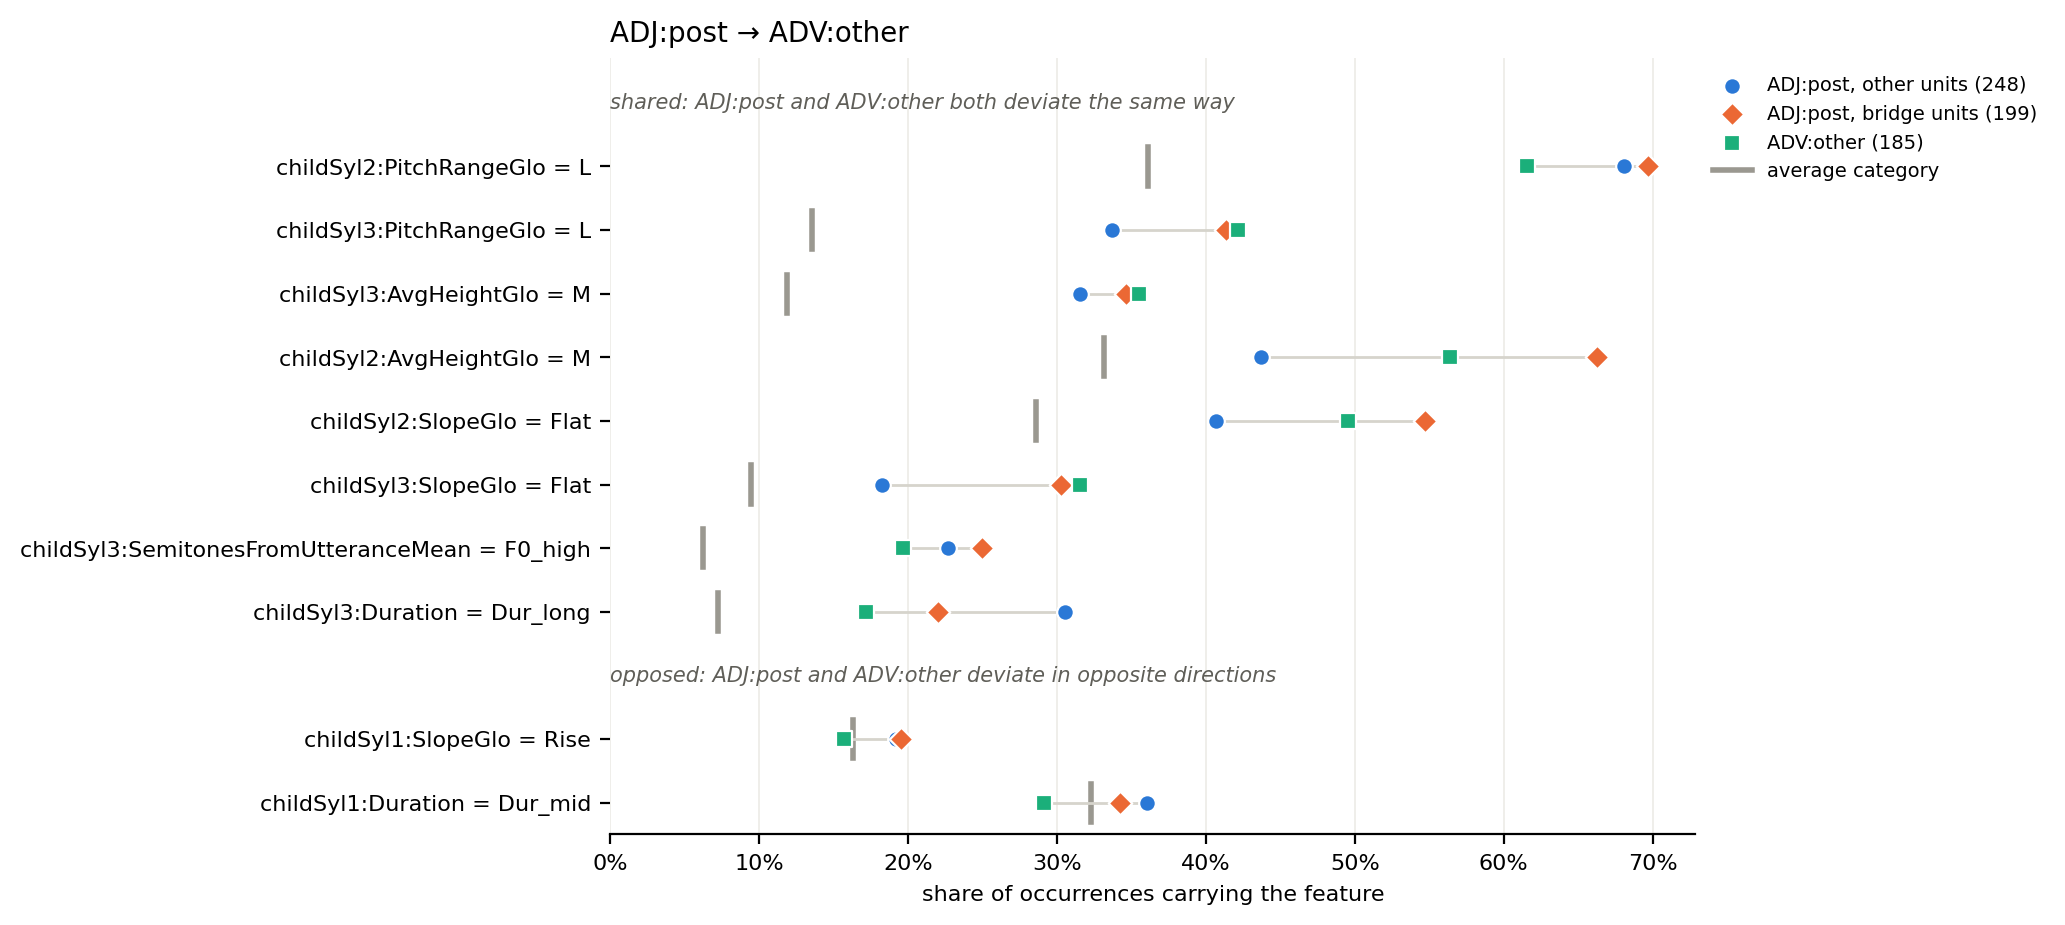

In [329]:
c0, c1 = "ADJ:head_dir=after_head", "ADV:Polarity=None"
print(region_table(c0, c1).round(3))
print(shared_table(c0, c1).head(15).round(3).to_string(index=False))
print(bridge_words(c0, c1).head(30).round(2).to_string(index=False))
print(bridge_constructions(c0, c1).head(15).round(2))
# plot_overlap(c0, c1); plt.tight_layout(); plt.savefig("det_adp.pdf")

# short names for figures:
SHORT = {"ADV:Polarity=Neg": "ADV:neg", "ADV:Polarity=None": "ADV:other",
         "PRON:head_dir=before_head": "PRON:pre", "PRON:head_dir=after_head": "PRON:post",
         "VERB:head_dir=before_head": "VERB:pre", "VERB:head_dir=after_head": "VERB:post",
         "NOUN:head_dir=before_head": "NOUN:pre", "NOUN:head_dir=after_head": "NOUN:post",
         "ADJ:head_dir=before_head": "ADJ:pre", "ADJ:head_dir=after_head": "ADJ:post"}
plot_overlap(c0, c1, short=SHORT)

In [330]:
t = shared_table(c0, c1)
t = t.loc[t.groupby("variable")["contrib"].apply(lambda s: s.abs().idxmax())]

shared = t[t["contrib"] > 0].nlargest(8, "contrib")
opposed = t[t["contrib"] < 0].nsmallest(4, "contrib")

print("SHARED")
print(shared[["feature", "variable", "region", "ref", "C0", "C1", "contrib"]]
      .round(4)
      .to_string(index=False))

print("\nOPPOSED")
print(opposed[["feature", "variable", "region", "ref", "C0", "C1", "contrib"]]
      .round(4)
      .to_string(index=False))

SHARED
                                     feature                             variable         region    ref     C0     C1  contrib
                   childSyl2:PitchRangeGlo=L              childSyl2:PitchRangeGlo own / syllable 0.3613 0.6881 0.6154   0.1137
                   childSyl3:PitchRangeGlo=L              childSyl3:PitchRangeGlo own / syllable 0.1354 0.3711 0.4215   0.0923
                    childSyl3:AvgHeightGlo=M               childSyl3:AvgHeightGlo own / syllable 0.1188 0.3291 0.3552   0.0681
                    childSyl2:AvgHeightGlo=M               childSyl2:AvgHeightGlo own / syllable 0.3313 0.5377 0.5640   0.0658
                     childSyl2:SlopeGlo=Flat                   childSyl2:SlopeGlo own / syllable 0.2860 0.4693 0.4956   0.0526
                     childSyl3:SlopeGlo=Flat                   childSyl3:SlopeGlo own / syllable 0.0943 0.2358 0.3153   0.0428
childSyl3:SemitonesFromUtteranceMean=F0_high childSyl3:SemitonesFromUtteranceMean own / syllable 0.0622 

In [331]:
print(compare_views(c0, c1)) 

{'rho': 0.8981777536919114, 'common_top_k': 14, 'resemblance_category': 0.8053984762551293, 'resemblance_bridge': 0.8876333886393848, 'n_bridge_units': 199, 'n_units': 447}


In [332]:
print(region_table(c0, c1).round(3))
print(compare_views(c0, c1))            # do category and bridge views agree?
print(region_table(c0, c1, who="bridge").round(3))
print(shared_table(c0, c1).head(15).round(3).to_string(index=False))
print(bridge_words(c0, c1).head(30).round(2).to_string(index=False))
print(bridge_constructions(c0, c1).head(15).round(2))

                   shared  opposed    net
region                                   
before / token        NaN      NaN    NaN
before / syllable   0.017   -0.002  0.015
own / token           NaN      NaN    NaN
own / syllable      0.772   -0.004  0.769
after / token         NaN      NaN    NaN
after / syllable    0.028   -0.006  0.022
total               0.817   -0.012  0.805
{'rho': 0.8981777536919114, 'common_top_k': 14, 'resemblance_category': 0.8053984762551293, 'resemblance_bridge': 0.8876333886393848, 'n_bridge_units': 199, 'n_units': 447}
                   shared  opposed    net
region                                   
before / token        NaN      NaN    NaN
before / syllable   0.021   -0.001  0.020
own / token           NaN      NaN    NaN
own / syllable      0.853   -0.003  0.850
after / token         NaN      NaN    NaN
after / syllable    0.018   -0.001  0.018
total               0.892   -0.005  0.888
                                     feature                           

In [333]:
import re
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
 
 
# ── A. Normalise after averaging, not unit by unit ──────────────────────
# The old version divided each unit's shares by category frequency and then
# made each unit's shares sum to 1. With only a few neighbours, that second
# step undoes the first: a unit whose only neighbour is a noun gets NOUN = 1
# whatever the size of NOUN. Averaging the raw shares over the row's units
# first, and dividing by frequency afterwards, keeps the correction intact:
# under random labels every cell is then 1/N.
# Paste this over the old stability() in the notebook (same inputs, same outputs),
# then rerun STEP 2 onwards. S (per-unit shares) is unchanged, so the bridge
# units do not change.
# def stability(W, has, labels, n_cats):
#     Y = np.eye(n_cats)[labels]
#     freq = Y.mean(0)                                  # freq(C) among units
#     P = np.asarray(W @ Y)                             # p(L, C): raw neighbourhood shares
#     counts = Y[has].sum(0)
#     raw = (Y[has].T @ P[has]) / np.maximum(counts, 1)[:, None]   # mean p(L, C) per row
#     mat = raw / freq                                  # how over-represented C is
#     mat = mat / mat.sum(1, keepdims=True)             # rows sum to 1
#     S = P / freq                                      # per unit, as before
#     S[has] /= S[has].sum(1, keepdims=True)
#     return mat, S
 
 
# ── Word length of each unit (number of syllables, most frequent value) ─
_syl = {}
for j, f in idx2feature.items():
    m = re.search(r"childSyl(\d)", f)
    if m:
        _syl.setdefault(int(m.group(1)), []).append(j)
_syl_cols = [np.array(_syl[k]) for k in sorted(_syl)]
 
 
def occ_length(i):
    """highest syllable position with any feature (0 if none)"""
    present = [k + 1 for k, cols in enumerate(_syl_cols) if OCC_M[i, cols].any()]
    return max(present) if present else 0
 
 
unit_len = np.array([
    np.bincount([occ_length(i) for i in unit_rows[u]]).argmax()
    for u in unique_units])
len_group = np.minimum(unit_len, 4)                  # 1, 2, 3, 4+ (0 = no syllable data)
print("units per length group:", dict(zip(*np.unique(len_group, return_counts=True))))
 
 
# ── B. Length-preserving chance level ───────────────────────────────────
# Shuffle category labels only among units of the same length. If the
# matrix were produced by word length alone, this shuffle would not change it.
def shuffle_within(groups, labels, rng):
    out = labels.copy()
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        out[idx] = rng.permutation(labels[idx])
    return out
 
 
rng = np.random.default_rng(0)
null_len = np.array([stability(W, has, shuffle_within(len_group, labels, rng), C)[0]
                     for _ in range(N_PERM)])
observed_new, _ = stability(W, has, labels, C)
diag = pd.DataFrame({"observed": np.diag(observed),
                        "chance (any word)": np.diag(null.mean(0)),
                        "chance (same length)": np.diag(null_len.mean(0))}, index=cats)
print(diag.round(3))
# for the block claim, reuse same_block_share() from step5_checks.py:
# np.mean([same_block_share(m) for m in null_len], axis=0)
 
 
# ── C. Classifier table ─────────────────────────────────────────────────
# A logistic regression guesses each unit's category from its features,
# always on units it was not trained on (5-fold cross-validation).
# Balanced accuracy = mean of per-category accuracies, so chance is 1/N.
CLOSED = {"ADP", "AUX", "CCONJ", "DET", "PRON", "SCONJ"}
is_closed_unit = np.array([cats[l].split(":")[0] in CLOSED for l in labels])
 
feature_sets = {
    "word length only": np.eye(5)[len_group],
    "acoustic": feature_matrix[:, [j for j, f in idx2feature.items()
                                   if any(m in f for m in ACOUSTIC_MEASURES)
                                   and "Tone" not in f]],
    "full": feature_matrix,
}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
clf = LogisticRegression(class_weight="balanced", max_iter=3000)
rows, confusions = [], {}
for name, X in feature_sets.items():
    pred = cross_val_predict(clf, X, labels, cv=cv)
    pred_closed = np.array([cats[p].split(":")[0] in CLOSED for p in pred])
    rows.append({"features": name, "n_features": X.shape[1],
                 "category (chance 1/N)": balanced_accuracy_score(labels, pred),
                 "grammatical vs lexical (chance 0.5)":
                     balanced_accuracy_score(is_closed_unit, pred_closed)})
    confusions[name] = pd.DataFrame(confusion_matrix(labels, pred, normalize="true"),
                                    index=cats, columns=cats)
print(f"chance = 1/{C} = {1/C:.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))
# confusions["full"] can be compared with the stability matrix (same rows/columns):
# print(np.corrcoef(confusions["full"].values[~np.eye(C, dtype=bool)],
#                   observed_new[~np.eye(C, dtype=bool)])[0, 1])
 

units per length group: {0: 128, 1: 840, 2: 1406, 3: 928, 4: 385}
                           observed  chance (any word)  chance (same length)
ADJ:head_dir=after_head       0.158              0.085                 0.129
ADJ:head_dir=before_head      0.113              0.063                 0.063
ADP                           0.250              0.048                 0.060
ADV:Polarity=Neg              0.214              0.020                 0.058
ADV:Polarity=None             0.232              0.076                 0.108
AUX                           0.230              0.055                 0.070
CCONJ                         0.121              0.033                 0.046
DET:head_dir=after_head       0.183              0.037                 0.049
DET:head_dir=before_head      0.150              0.065                 0.070
INTJ:head_dir=after_head      0.160              0.045                 0.051
INTJ:head_dir=before_head     0.345              0.033                 0.074
NOUN      

In [334]:
print(np.corrcoef(confusions["full"].values[~np.eye(C, dtype=bool)],
                  observed_new[~np.eye(C, dtype=bool)])[0, 1])

0.598649428962255


In [335]:
# ── STEP 5: numbers the revised paper still needs ────────────────────────
# Run after STEP 3 and STEP 4. Uses: observed, null, cats, C, labels, has,
# n_nbrs, feature_matrix, idx2feature, neighbour_weights, stability,
# cosine_similarity, split_results, overlap_table.
import re
import matplotlib.pyplot as plt
import seaborn as sns
 
CLOSED = {"ADP", "AUX", "CCONJ", "DET", "PRON", "SCONJ"}
is_closed = np.array([c.split(":")[0] in CLOSED for c in cats])
 
 
# 1. Median number of neighbours (Section 3, chance level) ----------------
print("median neighbours (units with any):", np.median(n_nbrs[has]))
 
 
# 2. Chance level per column, and the heatmap with a chance row -----------
chance_col = null.mean(0).mean(0)          # mean over shuffles, then over rows
 
 
def plot_stability(short=None, path=None, vmax=0.5):
    lab = [short.get(c, c) for c in cats] if short else cats
    fig, (ax, axc) = plt.subplots(
        2, 1, figsize=(9, 9.5), dpi=200, sharex=True,
        gridspec_kw={"height_ratios": [C, 1], "hspace": 0.04})
    kw = dict(cmap="YlOrRd", vmin=0, vmax=vmax, annot=True, fmt=".2f",
              annot_kws={"size": 7}, cbar=False, linewidths=0.4, linecolor="white")
    sns.heatmap(observed, ax=ax, xticklabels=lab, yticklabels=lab, **kw)
    sns.heatmap(chance_col[None, :], ax=axc, xticklabels=lab,
                yticklabels=["chance"], **kw)
    axc.tick_params(axis="x", rotation=90)
    ax.set_ylabel("category of the unit"); axc.set_xlabel("category of the neighbours")
    if path:
        fig.savefig(path, bbox_inches="tight")
    return fig
 
 
# 3. Same-block shares against their real chance level (Section 4.2) ------
def same_block_share(M):
    out = []
    for a in range(C):
        off = np.arange(C) != a
        same = off & (is_closed == is_closed[a])
        out.append(M[a, same].sum() / M[a, off].sum())
    return np.array(out)
 
 
blocks = pd.DataFrame({"closed": is_closed,
                       "observed": same_block_share(observed),
                       "chance": np.mean([same_block_share(m) for m in null], axis=0)},
                      index=cats)
print(blocks.round(2))
lex = ~blocks["closed"] & ~blocks.index.isin(["ADV:Polarity=Neg", "INTJ"])
print("grammatical rows:", blocks[blocks.closed][["observed", "chance"]].mean().round(2).to_dict())
print("lexical rows (without ADV:neg, INTJ):", blocks[lex][["observed", "chance"]].mean().round(2).to_dict())
 
 
# 4. VerbForm as a candidate division (Section 4.1) -----------------------
for cat in ("VERB", "AUX"):
    df = split_results.get(cat)
    if df is not None:
        print(cat, df[df["attr"] == "VerbForm"][["attr", "kappa", "p"]].round(3).to_string(index=False))
 
 
# 5. Word-length control (Limitations) ------------------------------------
keep = [j for j, f in idx2feature.items() if not re.search(r"childSyl[2-9]", f)]
W2, has2, _ = neighbour_weights(cosine_similarity(feature_matrix[:, keep]))
obs2, _ = stability(W2, has2, labels, C)
ov = overlap_table()
ov = ov[ov["kept"]]
ov["without_length"] = [obs2[cats.index(a), cats.index(b)] for a, b in zip(ov.C0, ov.C1)]
ov["self_without_length"] = [obs2[cats.index(a), cats.index(a)] for a in ov.C0]
print(f"dropped {feature_matrix.shape[1] - len(keep)} length columns")
print("mean diagonal:", np.diag(observed).mean().round(3), "->", np.diag(obs2).mean().round(3))
print(ov[["C0", "C1", "cell", "without_length", "self", "self_without_length"]].round(2).to_string(index=False))

median neighbours (units with any): 20.0
                           closed  observed  chance
ADJ:head_dir=after_head     False      0.79    0.57
ADJ:head_dir=before_head    False      0.54    0.58
ADP                          True      0.54    0.36
ADV:Polarity=Neg            False      0.18    0.60
ADV:Polarity=None           False      0.62    0.57
AUX                          True      0.56    0.36
CCONJ                        True      0.44    0.37
DET:head_dir=after_head      True      0.71    0.37
DET:head_dir=before_head     True      0.47    0.35
INTJ:head_dir=after_head    False      0.56    0.59
INTJ:head_dir=before_head   False      0.29    0.59
NOUN                        False      0.72    0.56
PRON:head_dir=after_head     True      0.39    0.35
PRON:head_dir=before_head    True      0.62    0.36
PROPN                       False      0.74    0.57
SCONJ                        True      0.73    0.38
VERB                        False      0.69    0.57
grammatical rows: {'obs

In [336]:
# ── STEP 7: three fixes to the numbers in STEPS 5–6 ──────────────────────
# Run after STEP 6 (needs: feature_sets, cv, labels, cats, null, null_len,
# same_block_share, is_closed).
 
# 1. Grammatical vs lexical: train a classifier on that question directly.
#    (Collapsing the 17-way predictions gave 0.44 for word length, below
#    chance: the balanced 17-way model sends short words to small lexical
#    categories such as ADV:neg or INTJ, so the collapsed answer is
#    not what a two-way classifier would do.)
is_closed_unit = np.array([cats[l].split(":")[0] in CLOSED for l in labels])
cv2 = StratifiedKFold(5, shuffle=True, random_state=0)
clf2 = LogisticRegression(class_weight="balanced", max_iter=3000)
for name, X in feature_sets.items():
    pred = cross_val_predict(clf2, X, is_closed_unit, cv=cv2)
    print(f"{name:18s} grammatical vs lexical: "
          f"{balanced_accuracy_score(is_closed_unit, pred):.3f}")
 
 
# 2. Block shares: ignore shuffles in which a row has no units with neighbours
#    (this happens to ADV:neg, 7 units, and caused the NaN).
def block_table(null_mats):
    vals = np.array([same_block_share(m) for m in null_mats])
    return np.nanmean(vals, axis=0)
 
 
blocks = pd.DataFrame({"closed": is_closed,
                       "observed": same_block_share(observed),
                       "chance": block_table(null),
                       "chance (same length)": block_table(null_len)}, index=cats)
print(blocks.round(2))
lex = ~blocks["closed"] & ~blocks.index.isin(["ADV:Polarity=Neg", "INTJ"])
print("grammatical rows:", blocks[blocks.closed].mean(numeric_only=True).round(2).to_dict())
print("lexical rows (without ADV:neg, INTJ):", blocks[lex].mean(numeric_only=True).round(2).to_dict())
 
 
# 3. Diagonal against both chance levels (the "any word" column was 1/N before)
print(pd.DataFrame({"observed": np.diag(observed),
                    "chance (any word)": np.diag(null.mean(0)),
                    "chance (same length)": np.diag(null_len.mean(0))},
                   index=cats).round(3))
 
 
# 4. Sensitivity to the neighbourhood parameters (Section 3, the 0.7 / 20 claim).
#    Units and categories stay as derived; only the neighbourhoods change.
import itertools
_saved = (SIM_THRESHOLD, MAX_NEIGHBOURS)
ov_kept = overlap_table()
ov_kept = ov_kept[ov_kept["kept"]][["C0", "C1"]].values.tolist()
sim_all = cosine_similarity(feature_matrix)
rows = []
for thr, cap in itertools.product([0.6, 0.7, 0.8], [10, 20, 30]):
    SIM_THRESHOLD, MAX_NEIGHBOURS = thr, cap
    Wp, hasp, _ = neighbour_weights(sim_all)
    Mp, _ = stability(Wp, hasp, labels, C)
    bs = same_block_share(Mp)
    still = sum(Mp[cats.index(a), cats.index(b)] >= Mp[cats.index(a), cats.index(a)]
                for a, b in ov_kept)
    rows.append({"threshold": thr, "max_neighbours": cap,
                 "units_with_neighbours": int(hasp.sum()),
                 "mean_diagonal": np.diag(Mp).mean(),
                 "grammatical_same_block": np.nanmean(bs[is_closed]),
                 "overlaps_still_>=_self": f"{still}/{len(ov_kept)}"})
SIM_THRESHOLD, MAX_NEIGHBOURS = _saved
print(pd.DataFrame(rows).round(3).to_string(index=False))
 

word length only   grammatical vs lexical: 0.723
acoustic           grammatical vs lexical: 0.782
full               grammatical vs lexical: 0.782
                           closed  observed  chance  chance (same length)
ADJ:head_dir=after_head     False      0.79    0.57                  0.70
ADJ:head_dir=before_head    False      0.54    0.58                  0.61
ADP                          True      0.54    0.36                  0.46
ADV:Polarity=Neg            False      0.18    0.60                  0.36
ADV:Polarity=None           False      0.62    0.57                  0.68
AUX                          True      0.56    0.36                  0.43
CCONJ                        True      0.44    0.37                  0.47
DET:head_dir=after_head      True      0.71    0.37                  0.48
DET:head_dir=before_head     True      0.47    0.35                  0.45
INTJ:head_dir=after_head    False      0.56    0.59                  0.48
INTJ:head_dir=before_head   False      

In [337]:
# ── STEP 8: which overlaps survive other neighbourhood settings? ─────────
# Run after STEP 7 (needs: ov_kept, sim_all, labels, cats, C, stability,
# neighbour_weights, N_PERM).
# The 12/12 at 0.7/20 is automatic: the overlaps were selected there.
# What matters is how often each one holds elsewhere.
import itertools
_saved = (SIM_THRESHOLD, MAX_NEIGHBOURS)
settings = list(itertools.product([0.6, 0.7, 0.8], [10, 20, 30]))
holds = {tuple(p): 0 for p in ov_kept}
ratio = {tuple(p): [] for p in ov_kept}
chance_diag = []
rng = np.random.default_rng(0)
for thr, cap in settings:
    SIM_THRESHOLD, MAX_NEIGHBOURS = thr, cap
    Wp, hasp, _ = neighbour_weights(sim_all)
    Mp, _ = stability(Wp, hasp, labels, C)
    for a, b in ov_kept:
        i, j = cats.index(a), cats.index(b)
        holds[(a, b)] += Mp[i, j] >= Mp[i, i]
        ratio[(a, b)].append(Mp[i, j] / Mp[i, i] if Mp[i, i] > 0 else np.nan)
    nulls = [stability(Wp, hasp, rng.permutation(labels), C)[0] for _ in range(100)]
    chance_diag.append((thr, cap, np.diag(Mp).mean(), np.mean([np.diag(m).mean() for m in nulls])))
SIM_THRESHOLD, MAX_NEIGHBOURS = _saved
 
print(pd.DataFrame(chance_diag, columns=["threshold", "max_nbrs", "mean_diagonal", "chance"]).round(3).to_string(index=False))
print()
print(pd.DataFrame([{"C0": a, "C1": b, "holds_in": f"{holds[(a, b)]}/9",
                     "cell/self min": np.nanmin(ratio[(a, b)]),
                     "cell/self max": np.nanmax(ratio[(a, b)])}
                    for a, b in ov_kept]).round(2).to_string(index=False))

 threshold  max_nbrs  mean_diagonal  chance
       0.6        10          0.211   0.059
       0.6        20          0.191   0.058
       0.6        30          0.176   0.057
       0.7        10          0.213   0.058
       0.7        20          0.187   0.058
       0.7        30          0.173   0.056
       0.8        10          0.218   0.058
       0.8        20          0.196   0.059
       0.8        30          0.187   0.057

                      C0                        C1 holds_in  cell/self min  cell/self max
                   CCONJ INTJ:head_dir=before_head      9/9           1.13           1.91
 DET:head_dir=after_head  DET:head_dir=before_head      3/9           0.27           1.39
 ADJ:head_dir=after_head                      NOUN      6/9           0.96           1.14
                   PROPN                      NOUN      9/9           1.01           1.24
                   CCONJ PRON:head_dir=before_head      2/9           0.54           1.41
                   

                   shared  opposed    net
region                                   
before / token        NaN      NaN    NaN
before / syllable   0.017   -0.002  0.015
own / token           NaN      NaN    NaN
own / syllable      0.772   -0.004  0.769
after / token         NaN      NaN    NaN
after / syllable    0.028   -0.006  0.022
total               0.817   -0.012  0.805
        unit  n_occ      own    rival
   définitif      1 0.000000 1.000000
    confiant      1 0.000000 0.897809
considérable      2 0.000000 0.896872
    cinglant      1 0.000000 0.893721
exceptionnel      2 0.000000 0.765404
     présent      5 0.083026 0.706102
     premier      2 0.000000 0.701188
      social     11 0.048784 0.699824
   déferlant      1 0.000000 0.697862
    nombreux      6 0.090878 0.660372
    national      6 0.230490 0.655818
    télévisé      1 0.090710 0.648606
démocratique      1 0.271479 0.648366
     heureux      7 0.000000 0.645362
    mobilisé      1 0.173307 0.636859
     mauvais  

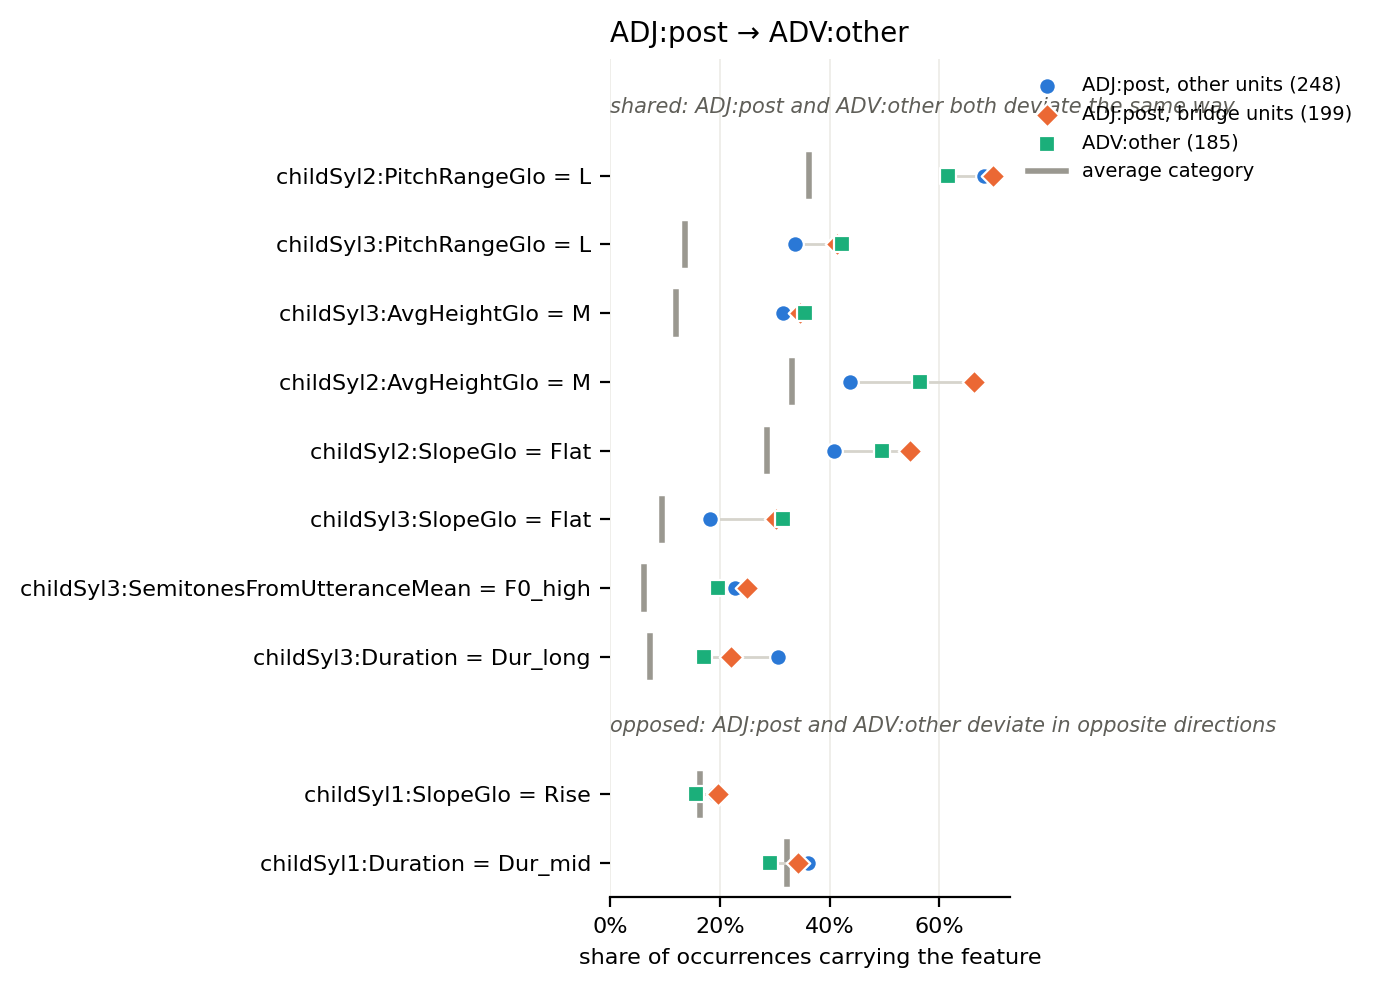

In [338]:
c0, c1 = "ADJ:head_dir=after_head", "ADV:Polarity=None"
print(region_table(c0, c1).round(3))
print(bridge_words(c0, c1).sort_values("rival", ascending=False).head(20).to_string(index=False))
plot_overlap(c0, c1, short=SHORT); plt.tight_layout(); plt.savefig("adjpost_advother.png")